# Agency and hindsight: does the dilemma survive, and what do people look like?

The teacher from `p5_simplest_teacher.ipynb` is `bayes3` (the original Bayesian model plus a solve-chance threshold, θ 0.45), found at agency 0, where shown moves teach nothing. This notebook asks whether the assistance dilemma, and bayes3's place in it, survive more realistic assumptions:

- **Agency 1:** shown moves teach as much as the student's own (with skipped update steps).
- **Limited hindsight:** the student notices shortcuts across its own wandering only between boards visited within W moves of each other (`scripts/p6_hindsight/`).
- **People:** which window, and which multiplier (simulated puzzles per human trial), make the people-calibrated student (`p3_session.ipynb`) learn like the 42 participants.
- **The website's puzzles:** one length range, 19-21 moves, for the human experiment.

The agency-1 runs build on the agency-0 run's settings (`RUN`, `SETTINGS` below).

In [2]:
import sys
sys.path.append("../scripts")
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import run_queue as rq
import session_analysis as sa  # the helpers p5 and p6 share: launching runs, reading results
import session_experiment as se
import teach_experiment as te
from session_analysis import OUT, argv, curve, entry, final, gains, learning, measures, paired, spend, watch

FIGURES = "../visualization/p6_hindsight"
# The agency-0 run of p5_simplest_teacher.ipynb, which the agency-1 runs here build on.
RUN = "teach_shortcut_agency0"  # every teacher here plays in the sweep's agency-0 run
NONE_RUN = "teach_shortcut_agency0.3"  # no teacher: the same at every agency, saved in the agency-0.3 run
# The run's settings (p4_dilemma.ipynb: START | shortcut labels | agency 0 with skipped steps).
SETTINGS = {"students": 8, "session_bins": ["9-11", "14-16", "19-21", "24-26"], "multiplier": 30, "per_bin": 18,
            "lr": 1e-4, "window": -1, "steps": 3, "max_attempts": 1, "surrender": True, "surrender_scale": 0.4,
            "test_per_bin": 50, "init": "../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt", "labels": "all",
            "shown_weight": 0.0, "agency_step": "skip"}


def launch(queue, teachers, run=RUN, settings=SETTINGS):
    """Plays `teachers` (specs) in `run` in the background (run_queue); does nothing for teachers already saved."""
    sa.launch(queue, teachers, run, settings)


def teacher_table(specs, against, run=RUN):
    """Spend, solves, how help was given, learning, and the end score against each of `against`, paired by student."""
    return sa.teacher_table(specs, against, run)

## Agency 1: is there still a dilemma, and where does bayes3 sit?

All the runs so far are at agency 0-0.3, chosen to make the assistance dilemma visible. There is no evidence that
people's agency is that low: the generation effect is moderate, and for novices worked examples often teach as much as
solving. Agency 1 was left out of the sweep because "help has no cost there". That rested on the first pilot, where
Adam cancelled the agency weight, so it was never measured with the current setup (skipped steps, shortcut labels).

**Agency 1** means a shown move teaches exactly what a move of the student's own does. Skipped steps never trigger, and
shown moves are optimal labels, better than the student's own. The prediction is that learning rises with help all the
way to full help, so the dilemma is gone. The run has the agency runs' settings with `shown_weight` 1, and
the same 8 students, session puzzles and tests (seed 0). No teacher comes from the agency-0.3 run as before, since
without help agency changes nothing.

| teacher | why |
|---|---|
| random 100% | the test of the dilemma: at agency 0 it learned nothing; at 0.3, +1.11 |
| bayes3 θ 0.45 | the default teacher, the same spec as at agency 0 |
| random 10% | random's peak at agency 0-0.3 |
| bayes3 θ 0.75 and 0.9 | more help from the same teacher, for its curve at this agency |
| random 30% | the middle of random's curve |

The queue runs them in that order, so a partial queue still answers the main question. About 25 minutes each on
the PC, so about 2.5 hours.

In [19]:
AGENCY1_RUN = "teach_shortcut_agency1"
AGENCY1_SETTINGS = {**SETTINGS, "shown_weight": 1.0}
AGENCY1 = ["random:1.0", "bayes3:0.45", "random:0.1", "bayes3:0.75", "bayes3:0.9", "random:0.3"]
launch("agency1", AGENCY1, run=AGENCY1_RUN, settings=AGENCY1_SETTINGS)

agency1 is already running (pid 20728)


In [20]:
watch("agency1")

agency1: 100%|██████████| , finished: 6.0/6 teacher runs in 2h20m                                                                   


,teacher,shown,solved as played,examples per puzzle,learning,vs no teacher,vs random 10%,vs random 30%
1,bayes3 0.45,0.035,0.877,38.889,+2.135 ± 0.048,+0.709 ± 0.088 (8/8),+0.248 ± 0.066 (8/8),+0.089 ± 0.068 (6/8)
3,bayes3 0.75,0.053,0.899,37.749,+2.153 ± 0.079,+0.727 ± 0.122 (8/8),+0.266 ± 0.079 (7/8),+0.106 ± 0.087 (5/8)
4,bayes3 0.9,0.091,0.923,34.616,+2.147 ± 0.024,+0.721 ± 0.057 (8/8),+0.261 ± 0.067 (8/8),+0.101 ± 0.064 (5/8)
2,random 0.1,0.100,0.838,32.126,+1.887 ± 0.067,+0.461 ± 0.082 (8/8),NaN,-0.160 ± 0.068 (1/8)
5,random 0.3,0.299,0.950,29.272,+2.047 ± 0.056,+0.620 ± 0.088 (8/8),+0.160 ± 0.068 (7/8),NaN
0,random 1.0,1.000,0.982,17.243,+1.756 ± 0.023,+0.330 ± 0.072 (8/8),-0.131 ± 0.078 (3/8),-0.291 ± 0.069 (0/8)


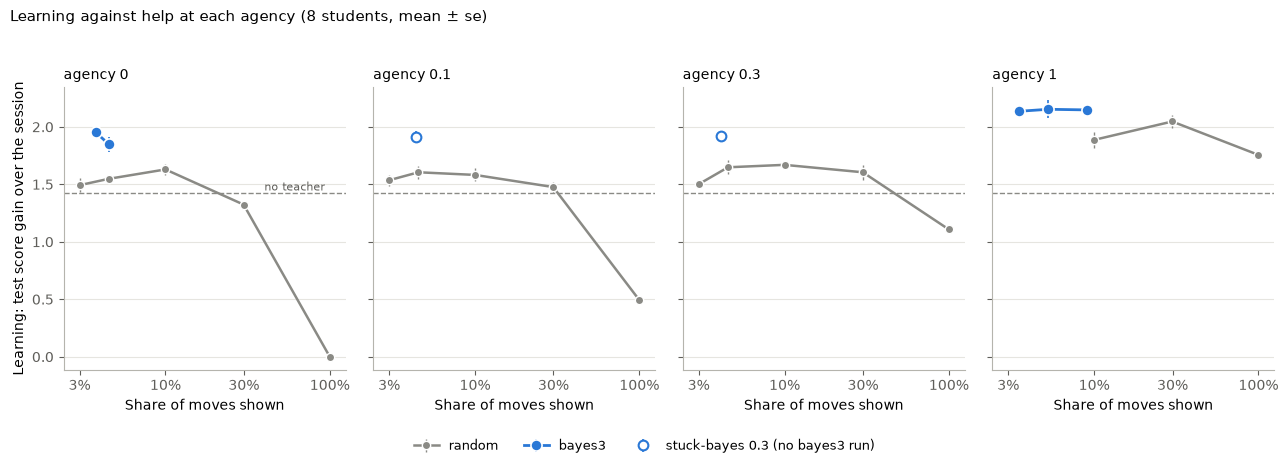

In [21]:
AGENCY_RUNS = {0: RUN, 0.1: "teach_shortcut_agency0.1", 0.3: "teach_shortcut_agency0.3", 1: AGENCY1_RUN}
RANDOM_ALL = ["random:0.03", "random:0.045", "random:0.1", "random:0.3", "random:1.0"]
BAYES3_AT = {0: ["stuck-bayes1:0.45,patience=0,giveup=0", "stuck-bayes1:0.6,patience=0,giveup=0"],
             1: ["bayes3:0.45", "bayes3:0.75", "bayes3:0.9"]}  # the same teacher, saved under its old name at agency 0
OTHER_AT = {0.1: ["stuck-bayes:0.3"], 0.3: ["stuck-bayes:0.3"]}  # bayes3 wasn't run there: the nearest targeted teacher


def gain(e, base):
    """Learning minus `base`'s, paired by student: (mean, se, k better, n)."""
    a, b = gains(e), gains(base)
    d = [a[s] - b[s] for s in a if s in b]
    m, s = te.mean_se(d)
    return m, s, sum(x > 0 for x in d), len(d)


def agency1_table(specs=None):
    none, rows = entry(NONE_RUN, "none"), []
    bases = [("vs no teacher", "none", none)] + [(f"vs random {p}", f"random:{q}", entry(AGENCY1_RUN, f"random:{q}"))
                                                 for p, q in (("10%", 0.1), ("30%", 0.3))]
    for spec in specs or AGENCY1:
        e = entry(AGENCY1_RUN, spec)
        if e is None:
            print(f"{se.teacher_name(spec)}: not saved yet")
            continue
        m, s = te.mean_se(learning(e))
        played = [x for r in e["sessions"].values() for x in r]
        row = {"teacher": se.teacher_name(spec), "shown": spend(e),
               "solved as played": np.mean([x["solved"] for x in played]),
               "examples per puzzle": np.mean([x["examples"] for x in played]),
               "learning": f"{m:+.3f} ± {s:.3f}"}
        for label, base_spec, base in bases:
            if base is not None and base_spec != spec:
                gm, gs, k, n = gain(e, base)
                row[label] = f"{gm:+.3f} ± {gs:.3f} ({k}/{n})"
        rows.append(row)
    return pd.DataFrame(rows).sort_values("shown").round(3)


def agency_figure(path):
    """Learning against help at each agency: random's curve (grey), bayes3 (blue), the nearest targeted teacher
    where bayes3 wasn't run (hollow blue), no teacher (dashed)."""
    agencies = list(AGENCY_RUNS)
    fig, axes = plt.subplots(1, len(agencies), figsize=(13, 4.6), sharey=True)
    base = np.mean(learning(entry(NONE_RUN, "none")))
    for ax, a in zip(axes, agencies):
        run = AGENCY_RUNS[a]
        ax.axhline(base, color="#8a8a85", lw=1, ls="--", zorder=0)
        pts = sorted((spend(e), *te.mean_se(learning(e))) for spec in RANDOM_ALL if (e := entry(run, spec)))
        if pts:
            x, m, s = map(np.array, zip(*pts))
            ax.errorbar(x, m, yerr=s, fmt="-o", color="#8a8a85", lw=1.8, ms=6, mec="white", mew=1, elinewidth=1,
                        capsize=0, label="random")
        pts = sorted((spend(e), *te.mean_se(learning(e))) for spec in BAYES3_AT.get(a, []) if (e := entry(run, spec)))
        if pts:
            x, m, s = map(np.array, zip(*pts))
            ax.errorbar(x, m, yerr=s, fmt="-o", color="#2a78d6", lw=2, ms=8, mec="white", mew=1.2, elinewidth=1.2,
                        capsize=0, label="bayes3", zorder=3)
        for spec in OTHER_AT.get(a, []):
            e = entry(run, spec)
            if e is not None:
                m, s = te.mean_se(learning(e))
                ax.errorbar(spend(e), m, yerr=s, fmt="o", color="#2a78d6", mfc="white", ms=7, mew=1.5,
                            elinewidth=1.2, capsize=0, label="stuck-bayes 0.3 (no bayes3 run)", zorder=3)
        ax.set_xscale("log")
        ax.set_xlim(0.024, 1.25)
        ax.set_xticks([0.03, 0.1, 0.3, 1.0], ["3%", "10%", "30%", "100%"])
        ax.minorticks_off()
        ax.set_title(f"agency {a:g}", fontsize=10, loc="left")
        ax.set_xlabel("Share of moves shown")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Learning: test score gain over the session")
    axes[0].text(0.4, base + 0.02, "no teacher", color="#5f5e5a", fontsize=8)
    handles = {}
    for ax in axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(l, h)
    fig.legend(handles.values(), handles.keys(), loc="lower center", ncol=len(handles), frameon=False, fontsize=9)
    fig.suptitle("Learning against help at each agency (8 students, mean ± se)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.07, 1, 0.95))
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


display(agency1_table())
agency_figure(os.path.join(FIGURES, "agency_curves.png"))

### Result: the dilemma survives at agency 1, and bayes3 is still the best teacher

**Full help still costs learning when shown moves teach fully.**
- Random 100% learns +1.76, 0.29 ± 0.07 less than random 30% (all 8 students worse) and 0.13 ± 0.08 less than random 10%.
- The prediction that learning would rise with help all the way to 100% was wrong.

**Why: help costs exploration, which agency doesn't touch.**
- The student learns from the shortest routes through every board its attempts visited (labels "all").
- A shown move keeps it on the optimal path. A fully shown puzzle leaves 17 examples, against 29-39 when the student wanders and finds its own way.
- So shown moves teach as much as found ones, but there are fewer of them, and none come from the boards the student would have got lost in.
- Lowering agency adds a second cost on top: what a shown move teaches.

**Random's peak moves right as agency rises.**
- About 8% shown at agency 0-0.1, 11% at 0.3, and somewhere between 10% and 100% at agency 1, near 30%.
- Agency 1 has only three random points, so its peak is rough.
- The high-help side keeps flattening: random 100% learns 0, +0.49, +1.11 and +1.76.

**bayes3 is flat from 3.5% to 9% shown at agency 1, and beats every random setting.**
- θ 0.45, 0.75 and 0.9 learn +2.14, +2.15 and +2.15.
- That is about 0.25 more than random 10% (7-8/8 students).
- It is about 0.1 more than random 30%, the best random setting at this agency (5-6/8 students, each about 1.5 se).
- bayes3's lead over the best random help shrinks with agency: +0.32 at agency 0 (against random 10%), +0.1 here.
- bayes3's curve isn't bracketed: it hasn't started to fall by 9%. So the help it should give at agency 1 is unknown beyond "at least 3.5%, and θ hardly matters up to 9%".
- At θ 0.45 spend is about the same as at agency 0 (3.5% against 3.8%), and learning is higher (+2.14 against +1.95), since the shown moves now count.

**Why the earlier pilot showed no dilemma at full agency.** The sweep notebook skipped agency 1 because of its first pilot. There, learning rose with help all the way to full help. That pilot was nominally at agency 0.1, but Adam cancelled the weight, and it cancelled it unevenly:
- With every move shown, every example in a batch weighs 0.1. Adam rescales that away, so full help ran at agency 1.
- With partial help, shown and own moves share a batch, and the 0.1 still counts between them. Shown moves taught a tenth as much as the student's own, so partial help ran at about agency 0.1.

So the pilot compared full help at agency 1 with partial help at agency 0.1, which favoured full help. Test scores after about 540 puzzles show this (the pilot tested at 360 and 720 puzzles, so its figures are interpolated):

| | pilot (about 540) | this run (540) |
|---|---|---|
| no teacher | about 4.92 | 4.78 (agency-0.3 run) |
| random 100% | about 4.66 | 4.64 |
| random 30% | about 4.73 | 4.41 |
| random 10% | about 4.79 | 4.50 |

Full help learns at the same rate in both. Partial help learns much faster once its shown moves count fully. The difference isn't session length: in this run random 100% is already 0.23 behind random 30% at 540 puzzles, and stays 0.3 behind to the end.

**For the question of realistic agency:** the assistance dilemma in this model doesn't depend on agency being very low. At agency 1 too much help still hurts, because it takes away the student's own search. And a teacher that helps only when the student is likely stuck still does best.

## Agency 1: where does bayes3's curve fall?

At agency 1, bayes3 learned the same at θ 0.45, 0.75 and 0.9 (3.5% to 9% shown), so the run didn't find where more
help starts to cost. Here bayes3 runs at higher thresholds, in the same run (same students, puzzles and tests).
Spend has grown by about 1.6× for each step of about 1.1 in logit θ (0.45 → 0.75 → 0.9), so:

- **θ 0.99:** expected near 30% shown, the same help as random's best setting at this agency. This is a direct comparison of when to help at the same amount.
- **θ 0.97:** expected around 15%.
- **θ 0.999:** expected well above 30%, to see the high-help side.

These are extrapolations. The solve chance may saturate, so the real spend is read from the run.

In [ ]:
AGENCY1_HIGH = ["bayes3:0.99", "bayes3:0.97", "bayes3:0.999"]
launch("agency1_high", AGENCY1_HIGH, run=AGENCY1_RUN, settings=AGENCY1_SETTINGS)

In [ ]:
watch("agency1_high")

In [ ]:
BAYES3_AT[1] = ["bayes3:0.45", "bayes3:0.75", "bayes3:0.9", "bayes3:0.97", "bayes3:0.99", "bayes3:0.999"]
display(agency1_table(AGENCY1 + AGENCY1_HIGH))
agency_figure(os.path.join(FIGURES, "agency_curves.png"))

### Result: bayes3 at agency 1 is flat up to about 9% shown and falls beyond that

| bayes3 θ | shown | examples per puzzle | learning | vs random 30% |
|---|---|---|---|---|
| 0.45 | 3.5% | 38.9 | +2.14 | +0.09 ± 0.07 (6/8) |
| 0.75 | 5.3% | 37.7 | +2.15 | +0.11 ± 0.09 (5/8) |
| 0.9 | 9.1% | 34.6 | +2.15 | +0.10 ± 0.06 (5/8) |
| 0.97 | 22% | 28.5 | +1.97 | −0.08 ± 0.06 (4/8) |
| 0.99 | 40% | 23.3 | +1.95 | −0.09 ± 0.06 (3/8) |
| 0.999 | 100% | 17.2 | +1.76 | −0.29 ± 0.07 (0/8) |

- **The curve is a plateau, then a decline.** bayes3 learns the same from 3.5% to 9% shown, then about 0.18 less at 22% and 40%, and 0.39 less at 100%.
  - A quadratic in log(share shown), as fitted at agency 0, doesn't describe a plateau: it puts the peak at 2.6% with an interval from 0% to 8%. So it isn't used here.
  - The useful summary is that anything from θ 0.45 to 0.9 is equally good at agency 1, and θ 0.45 stays the default.
- **At θ 0.999 bayes3 shows every move.** The model never gives the student a solve-alone chance above 0.999, so this is full help, and it matches random 100% (+1.76, the same examples).
- **At high help, targeted help no longer beats random.** At 22% and 40% shown, bayes3 is slightly below random 30% (−0.08 and −0.09, not significant).
  - The likely reason is the take-over pattern. With a high θ, once bayes3 steps in it keeps showing moves until the solve chance clears θ, so it removes whole stretches of the student's search. Random help spreads the same number of shown moves out.
  - The examples per puzzle fit this. bayes3 at 22% shown leaves 28.5 examples per puzzle, against 29.3 for random at 30%.
- **Overall at agency 1:** light targeted help (3.5–9%) is best, at about +2.15. That is about 0.1 above random's best (30%) and 0.39 above full help. Learning roughly follows the examples the student's own search produces: across the nine teachers, the more examples per puzzle, the more learning. The exception is random 10%, which learns less than its 32 examples per puzzle would suggest. Example count isn't the whole story.

## Limited hindsight: which labels survive?

Shortcut labels assume the student remembers every board it visited and notices every one-move connection between
them. People can't do that. This checks, without training anything, how much of what made shortcut labels work
survives a human-like limit.

`scripts/p6_hindsight/hindsight_labels.py` has the starting network play 600 session puzzles (150 per bin, as in the agency-1
run: temperature 1, memory 10, a cap of max(50, 10 d), giving up at 0.4× people's rates). It then labels each solved
attempt in several ways, and scores every label against exact (BFS) distances:

- **own:** the path played with loops cut out, the labels used before shortcut labels;
- **walk (W=1):** shortest routes using only the moves actually played;
- **W = w:** shortcut labels, but a one-move connection between two visited boards is noticed only if the student was
  at them within w moves of each other. W = inf is today's "all" labels;
- **path:** today's "path" labels (boards on shortest routes from the start);
- **near D:** shortcut labels only on boards at most D moves from the goal: label less, but only what is reliable.

"Off-path" boards lie off every optimal path from the start: coverage a fully shown solution never gives.

In [ ]:
import json

HINDSIGHT = json.load(open(os.path.join(OUT, "hindsight_labels.json")))
print(f"{HINDSIGHT['n']} puzzles, {HINDSIGHT['solved']} solved")
display(pd.DataFrame(HINDSIGHT["table"]).set_index("labels").round(3))

### Result: a recency window keeps the coverage and most of the label quality

| labels | labels per puzzle | off-path | targets optimal | distance / true |
|---|---|---|---|---|
| own | 24.0 | 16.4 | 54.5% | 2.42 |
| walk (W=1) | 32.3 | 23.3 | 51.2% | 2.35 |
| W=5 | 32.3 | 23.3 | 56.5% | 1.81 |
| W=10 | 32.3 | 23.3 | 58.9% | 1.68 |
| W=20 | 32.3 | 23.3 | 60.6% | 1.61 |
| W=inf (all) | 32.3 | 23.3 | 63.3% | 1.56 |
| path | 16.2 | 9.5 | 71.3% | 1.50 |
| near 10 | 9.3 | 6.3 | 69.6% | 1.34 |
| near 5 | 3.9 | 2.5 | 77.8% | 1.22 |

**Coverage doesn't need full hindsight.**
- Every windowed variant labels the same 32 boards per puzzle, 23 of them off every optimal path. The moves the student actually played always link each visited board to the goal. A window changes how good the labels are, not which boards get one.
- Own labels lose a quarter of those boards, because cutting loops discards the boards inside them.

**Label quality falls gradually as the window shrinks.**
- W=10 has 1.68× the true distance against 1.56× for full hindsight and 2.42× for own labels. That is 86% of full hindsight's improvement in distance, and about half of its improvement in optimal targets (58.9% against 63.3%, from 54.5%).
- W=5 keeps 70% of the distance improvement but only about a quarter of the improvement in target moves.
- With no shortcuts at all (W=1), the target moves are worse than own labels (51%), since the boards inside loops are now labelled too.

**Harder puzzles need a longer window.** On 24-26 move puzzles, W=10 reaches 60% optimal targets against 67% with full hindsight. On 9-11 move puzzles it reaches 60% against 62%.

**Labelling only near the goal trades away coverage.** The labels are much better (70-78% optimal, 1.2-1.3×), but there are only 4-9 per puzzle, and 2-6 off-path. That removes most of what the student gains by exploring, so it would likely weaken the exploration effect the most.

**What this doesn't settle.** It doesn't show which property drives learning and the dilemma: the number of labels, distance accuracy, or move accuracy. That needs training.
- The offline test in the sweep notebook showed shortcut labels learning far more than own labels, but it didn't separate these properties.
- These attempts are the starting network's. Later in a session, attempts get shorter and loops rarer.

**Next:** short agency-1 sessions with W=10 and W=5 (and own labels as the control), each with random 30% and 100%. These would show whether the dilemma survives a human-like limit on hindsight.

## Does the dilemma survive limited hindsight? Agency 1 at W = 10, W = 5 and own labels

The label analysis above showed that a recency window keeps every visited board labelled but makes the labels less
accurate. Here the window goes into the student (`--window` now also limits shortcut labels: rl.shortcut_routes
notices a connection only between boards visited within W moves of each other). Each label setting gets its own run
at agency 1, with the agency-1 run's settings, students, puzzles and tests otherwise:

- **W = 10** and **W = 5:** limited hindsight;
- **own labels** (loops cut out, no shortcuts): the student before shortcut labels, with which more help always
  seemed better. This is the control for the explanation that shortcut labels are what make exploration pay.

Each has no teacher, random 30% (random's best at agency 1 with full hindsight) and random 100%. No teacher learns
differently under each label setting, so each needs its own. Full hindsight is the agency-1 run above (no teacher
from the agency-0.3 run, which is the same student with no shown moves).

**The question:** is random 100% still below random 30%? With full hindsight it is 0.29 ± 0.07 below. Nine teacher runs,
about 3 hours, queued in the order W = 10, own, W = 5.

In [ ]:
HINDSIGHT_TEACHERS = ["random:1.0", "random:0.3", "none"]
HINDSIGHT_RUNS = {"W=10": ("teach_shortcut_agency1_w10", {**AGENCY1_SETTINGS, "window": 10}),
                  "own": ("teach_own_agency1", {**AGENCY1_SETTINGS, "labels": "own"}),
                  "W=5": ("teach_shortcut_agency1_w5", {**AGENCY1_SETTINGS, "window": 5})}
os.chdir("../scripts")  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("hindsight_agency1", [(run, argv(s) + ["--teachers", *HINDSIGHT_TEACHERS])
                                    for run, s in HINDSIGHT_RUNS.values()])
finally:
    os.chdir("../notebooks")

In [ ]:
watch("hindsight_agency1")

In [ ]:
HINDSIGHT_ALL = {"full (W=inf)": (AGENCY1_RUN, NONE_RUN)} | {k: (run, run) for k, (run, _) in HINDSIGHT_RUNS.items()}
HINDSIGHT_ORDER = ["full (W=inf)", "W=10", "W=5", "own"]


def hindsight_table():
    """Per label setting: each teacher's learning, and the paired differences that matter."""
    rows = []
    for name in HINDSIGHT_ORDER:
        run, none_run = HINDSIGHT_ALL[name]
        e = {"none": entry(none_run, "none"), "random:0.3": entry(run, "random:0.3"), "random:1.0": entry(run, "random:1.0")}
        row = {"hindsight": name}
        for spec, x in e.items():
            if x is None:
                row[se.teacher_name(spec)] = "not saved yet"
                continue
            m, s = te.mean_se(learning(x))
            played = [r for rec in x["sessions"].values() for r in rec]
            row[se.teacher_name(spec)] = f"{m:+.3f} ± {s:.3f}"
            row[f"examples ({spec.split(':')[-1]})"] = round(np.mean([r["examples"] for r in played]), 1)
            row[f"solved ({spec.split(':')[-1]})"] = round(np.mean([r["solved"] for r in played]), 2)
        for label, a, b in (("30% vs none", "random:0.3", "none"), ("100% vs 30%", "random:1.0", "random:0.3")):
            if e[a] is not None and e[b] is not None:
                gm, gs, k, n = gain(e[a], e[b])
                row[label] = f"{gm:+.3f} ± {gs:.3f} ({k}/{n})"
        rows.append(row)
    return pd.DataFrame(rows).set_index("hindsight")


def hindsight_figure(path):
    """Learning against help (none, 30%, 100%) at agency 1, one line per label setting."""
    fig, ax = plt.subplots(figsize=(8, 5))
    colors = {"full (W=inf)": "#1f1f1d", "W=10": "#2a78d6", "W=5": "#7fb2ea", "own": "#eb6834"}
    for name in HINDSIGHT_ORDER:
        run, none_run = HINDSIGHT_ALL[name]
        pts = []
        for x_pos, spec, r in ((0.01, "none", none_run), (0.3, "random:0.3", run), (1.0, "random:1.0", run)):
            e = entry(r, spec)
            if e is not None:
                pts.append((x_pos, *te.mean_se(learning(e))))
        if pts:
            x, m, s = map(np.array, zip(*pts))
            ax.errorbar(x, m, yerr=s, fmt="-o", color=colors[name], lw=2, ms=7, mec="white", mew=1.2,
                        elinewidth=1.2, capsize=0, label=name)
    ax.legend(title="hindsight", loc="lower right", frameon=False, fontsize=9, title_fontsize=9)
    ax.set_xscale("log")
    ax.set_xlim(0.007, 1.5)
    ax.set_xticks([0.01, 0.3, 1.0], ["no teacher", "random 30%", "random 100%"])
    ax.minorticks_off()
    ax.set_ylabel("Learning: test score gain over the session")
    ax.set_title("Agency 1: learning against help, by how much hindsight the student has (8 students, mean ± se)",
                 fontsize=10, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4ad")
    ax.tick_params(colors="#5f5e5a")
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


display(hindsight_table())
hindsight_figure(os.path.join(FIGURES, "hindsight_agency1.png"))

### Result: the dilemma comes from shortcut labels, and survives a 10-move hindsight window

| hindsight | no teacher | random 30% | random 100% | 100% vs 30% (paired) |
|---|---|---|---|---|
| full (W=inf) | +1.43 | +2.05 | +1.76 | −0.29 ± 0.07 (0/8 better) |
| W=10 | +1.35 | +2.01 | +1.72 | −0.30 ± 0.03 (0/8) |
| W=5 | +1.12 | +1.90 | +1.68 | −0.22 ± 0.06 (2/8) |
| own labels | +0.01 | +1.39 | +1.76 | **+0.37 ± 0.03 (8/8)** |

- **Own labels: no dilemma.** More help is better at every step, as in the runs before shortcut labels.
  - Left alone, the student learns nothing (+0.01): its loop-cut paths are poor targets, so 23 examples a puzzle
    of its own play are worth nothing.
  - Random 100% beats random 30% by 0.37 for all 8 students.
  - This confirms the explanation in the agency-1 section: the dilemma needs a student who can learn from its own
    wandering, and here that ability comes from shortcut labels. Agency 1 by itself does not produce it.
- **A 10-move window keeps all of it.** 100% vs 30% is −0.30 (0/8), the same as full hindsight. No teacher drops
  only 0.08.
- **A 5-move window keeps most of it.** The gap shrinks to −0.22 (2/8 students go the other way). The student's own
  play is worth less (no teacher +1.12), so a little help is worth more (30% vs none +0.78, against +0.62).
- **Random 100% is the same in every row** (17.2 examples, 98% solved), as it should be: a fully shown solution has
  no wandering, so every label setting gives the same labels. The spread of 0.08 across rows (+1.68 to +1.76) is
  therefore run-to-run noise. Comparisons across rows are not paired by run and should be read against that.
- **The order matches the label analysis.** The shorter the window, the less the student gains from its own play,
  and the smaller the dilemma. The analysis predicted W=10 would keep most of the distance accuracy, and it does.

**What this means for the model.** The assistance dilemma here rests on one assumption: that a learner who solves
a puzzle can work out, afterwards, better routes through the boards it visited. Limiting that to boards visited
within 10 moves of each other, which is closer to human memory, loses none of the effect. A student who can only
reuse its own path with loops cut out shows no dilemma at all. Whether people learn like the shortcut student or the
own-labels student is now the key empirical question, and the two predict opposite effects of full help.

## Exploring the hindsight window

Four analyses of how limited hindsight shapes the dilemma and the teacher, all at agency 1:

1. **When in the session** the cost of full help appears, at each window (the test snapshots after 540, 1080, 1620 and 2160 puzzles).
2. **Which puzzle lengths** carry it: the end-of-session gap on each test-length bin.
3. **What bayes3's help does to the labels**: a replay of the session start with each teacher, labelled at each window (`scripts/p6_hindsight/hindsight_teacher_labels.py`).
4. **bayes3 across the help range at each window**: θ 0.45, 0.9, 0.97 (and 0.99 at W=5 and own), in the W=10, W=5 and own-label runs.

Two more sets of runs feed these:
- **Lower windows at agency 1:** W=3 and W=1 with no teacher, random 30% and random 100%.
- **The people-calibrated student** (`p3_session.ipynb`: the humans' puzzle lengths, starting level and giving up) with no teacher, under own labels and W = 1, 3, 5, 10 and unlimited. Its learning is compared with people's, to see which window people's learning looks like. The agency-1 runs use much longer puzzles, so they can't be compared with people.

One queue, 23 teacher runs, about 8 hours.

In [ ]:
# Lower windows at agency 1 (no teacher, random 30%, random 100%), as for W=10 and W=5.
LOW_W_RUNS = {"W=3": ("teach_shortcut_agency1_w3", {**AGENCY1_SETTINGS, "window": 3}),
              "W=1": ("teach_shortcut_agency1_w1", {**AGENCY1_SETTINGS, "window": 1})}
# The people-calibrated student (p3_session.ipynb's CALIBRATED: the humans' puzzle lengths, own labels),
# with no teacher, under each kind of hindsight.
INIT = "../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt"
PEOPLE_SETTINGS = {"students": 8, "multiplier": 30, "lr": 1e-4, "window": -1, "steps": 3, "max_attempts": 1,
                   "surrender": True, "test_surrender": True, "surrender_scale": 0.4, "init": INIT}
PEOPLE_RUNS = {"own": ("people_own", {**PEOPLE_SETTINGS, "labels": "own"}),
               "W=1": ("people_w1", {**PEOPLE_SETTINGS, "labels": "all", "window": 1}),
               "W=3": ("people_w3", {**PEOPLE_SETTINGS, "labels": "all", "window": 3}),
               "W=5": ("people_w5", {**PEOPLE_SETTINGS, "labels": "all", "window": 5}),
               "W=10": ("people_w10", {**PEOPLE_SETTINGS, "labels": "all", "window": 10}),
               "full (W=inf)": ("people_all", {**PEOPLE_SETTINGS, "labels": "all", "window": -1})}
# bayes3 across the help range at each window (full hindsight already has θ 0.45-0.999).
BAYES3_W = {"W=10": ["bayes3:0.45", "bayes3:0.9", "bayes3:0.97"],
            "W=5": ["bayes3:0.45", "bayes3:0.9", "bayes3:0.97", "bayes3:0.99"],
            "own": ["bayes3:0.45", "bayes3:0.9", "bayes3:0.97", "bayes3:0.99"]}

jobs = ([(run, argv(s) + ["--teachers", "none", "random:0.3", "random:1.0"]) for run, s in LOW_W_RUNS.values()]
        + [(run, argv(s) + ["--teachers", "none"]) for run, s in PEOPLE_RUNS.values()]
        + [(HINDSIGHT_RUNS[w][0], argv(HINDSIGHT_RUNS[w][1]) + ["--teachers", *specs]) for w, specs in BAYES3_W.items()])
os.chdir("../scripts")  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("hindsight_explore", jobs)
finally:
    os.chdir("../notebooks")

In [ ]:
watch("hindsight_explore")

In [ ]:
WINDOWS = {"full (W=inf)": (AGENCY1_RUN, NONE_RUN), "W=10": (HINDSIGHT_RUNS["W=10"][0],) * 2,
           "W=5": (HINDSIGHT_RUNS["W=5"][0],) * 2, "W=3": (LOW_W_RUNS["W=3"][0],) * 2,
           "W=1": (LOW_W_RUNS["W=1"][0],) * 2, "own": (HINDSIGHT_RUNS["own"][0],) * 2}
WINDOW_COLORS = {"full (W=inf)": "#1f1f1d", "W=10": "#1c5aa8", "W=5": "#2a78d6", "W=3": "#7fb2ea", "W=1": "#b9d5f5",
                 "own": "#eb6834"}


def window_entries(name):
    """{"none", "random:0.3", "random:1.0"} entries of a hindsight setting (None where not saved)."""
    run, none_run = WINDOWS[name]
    return {"none": entry(none_run, "none"), "random:0.3": entry(run, "random:0.3"),
            "random:1.0": entry(run, "random:1.0")}


def scores_at(e, n, lo=None, hi=None):
    """{student: test score after n puzzles}, over the test puzzles of optimal length lo..hi (default: all)."""
    out = {}
    for s, by_n in e["results"].items():
        if n in by_n:
            a = [x for x in by_n[n] if lo is None or lo <= x["distance"] <= hi]
            out[s] = measures(a, e["config"])[0]
    return out


def gap(a, b, n, lo=None, hi=None):
    """Learning of a minus learning of b after n puzzles, paired by student (a lower score is better):
    (mean, se, students where a is ahead, students)."""
    sa, sb = scores_at(a, n, lo, hi), scores_at(b, n, lo, hi)
    d = [sb[s] - sa[s] for s in sa if s in sb]
    m, s = te.mean_se(d)
    return m, s, sum(x > 0 for x in d), len(d)


def fmt(g):
    return f"{g[0]:+.2f} ± {g[1]:.2f} ({g[2]}/{g[3]})"


def saved_windows():
    return [w for w in WINDOWS if all(v is not None for v in window_entries(w).values())]


def time_table():
    """Per window and test point: 30% vs none and 100% vs 30%."""
    rows = []
    for w in saved_windows():
        e = window_entries(w)
        points = sorted(n for n in e["none"]["results"][0] if n > 0)
        for label, a, b in (("30% vs none", "random:0.3", "none"), ("100% vs 30%", "random:1.0", "random:0.3")):
            rows.append({"hindsight": w, "comparison": label} | {f"after {n}": fmt(gap(e[a], e[b], n)) for n in points})
    return pd.DataFrame(rows).set_index(["hindsight", "comparison"])


def time_figure(path):
    """Learning along the session, one panel per window: no teacher (dashed), random 30%, random 100%."""
    ws = saved_windows()
    fig, axes = plt.subplots(1, len(ws), figsize=(3.1 * len(ws), 3.8), sharey=True)
    styles = {"none": ("#8a8a85", "--", "no teacher"), "random:0.3": ("#2a78d6", "-", "random 30%"),
              "random:1.0": ("#eb6834", "-", "random 100%")}
    for ax, w in zip(np.atleast_1d(axes), ws):
        e = window_entries(w)
        start = measures(e["none"]["results"][0][0], e["none"]["config"])[0]
        for spec, (c, ls, label) in styles.items():
            pts = [(n, *te.mean_se([start - v for v in scores_at(e[spec], n).values()]))
                   for n in sorted(e[spec]["results"][0])]
            x, m, s = map(np.array, zip(*pts))
            ax.fill_between(x, m - s, m + s, color=c, alpha=0.15, lw=0)
            ax.plot(x, m, ls, color=c, lw=2, marker="o", ms=5, mec="white", mew=1, label=label)
        ax.set_title(w, fontsize=10, loc="left")
        ax.set_xticks([0, 1080, 2160])
        ax.set_xlabel("Puzzles played")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Learning so far (test score gain)")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=9)
    fig.suptitle("Agency 1: learning along the session, by hindsight (8 students, mean ± se)", x=0.01, ha="left",
                 fontsize=11)
    plt.tight_layout(rect=(0, 0.08, 1, 0.94))
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


def examples_in(e, lo, hi):
    """Training examples per session puzzle of optimal length lo..hi."""
    return np.mean([x["examples"] for rec in e["sessions"].values() for x in rec if lo <= x["distance"] <= hi])


def bin_figure(path):
    """100% vs 30% at the end of the session, by test-puzzle length, one line per window."""
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    ax.axhline(0, color="#8a8a85", lw=1)
    for w in saved_windows():
        e = window_entries(w)
        end = max(e["none"]["results"][0])
        bins = e["none"]["config"]["test_bins"]
        pts = [gap(e["random:1.0"], e["random:0.3"], end, *map(int, b.split("-")))[:2] for b in bins]
        m, s = map(np.array, zip(*pts))
        x = np.arange(len(bins))
        ax.errorbar(x, m, yerr=s, fmt="-o", color=WINDOW_COLORS[w], lw=2, ms=7, mec="white", mew=1.2,
                    elinewidth=1.2, capsize=0, label=w)
    ax.set_xticks(np.arange(len(bins)), [f"{b} moves" for b in bins])
    ax.set_xlabel("Test puzzles' optimal length")
    ax.set_ylabel("Learning: random 100% minus random 30%")
    ax.text(len(bins) - 1, 0.03, "full help better", ha="right", va="bottom", fontsize=9, color="#5f5e5a")
    ax.text(len(bins) - 1, -0.03, "full help worse", ha="right", va="top", fontsize=9, color="#5f5e5a")
    ax.legend(title="hindsight", frameon=False, fontsize=9, title_fontsize=9, loc="lower left")
    ax.set_title("Agency 1: the cost of full help, by puzzle length (end of session, 8 students, mean ± se)",
                 fontsize=10, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4ad")
    ax.tick_params(colors="#5f5e5a")
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


def bin_table():
    """Per window and test-puzzle length bin, at the end of the session: no teacher's learning, and the gaps."""
    rows = []
    for w in saved_windows():
        e = window_entries(w)
        end = max(e["none"]["results"][0])
        start_all = e["none"]["results"][0][0]
        for b in e["none"]["config"]["test_bins"]:
            lo, hi = map(int, b.split("-"))
            start = measures([x for x in start_all if lo <= x["distance"] <= hi], e["none"]["config"])[0]
            m, s = te.mean_se([start - v for v in scores_at(e["none"], end, lo, hi).values()])
            rows.append({"hindsight": w, "length": b, "start score": round(start, 2),
                         "no teacher learns": f"{m:+.2f} ± {s:.2f}",
                         "30% vs none": fmt(gap(e["random:0.3"], e["none"], end, lo, hi)),
                         "100% vs 30%": fmt(gap(e["random:1.0"], e["random:0.3"], end, lo, hi)),
                         "examples: none": examples_in(e["none"], lo, hi),
                         "examples: 30%": examples_in(e["random:0.3"], lo, hi),
                         "examples: 100%": examples_in(e["random:1.0"], lo, hi)})
    return pd.DataFrame(rows).set_index(["hindsight", "length"]).round(3)


display(time_table())
time_figure(os.path.join(FIGURES, "hindsight_time.png"))
display(bin_table())
bin_figure(os.path.join(FIGURES, "hindsight_by_length.png"))

### 1-2. Results: when the cost appears, and on which puzzles

**Lower windows.** The dilemma ends between W=5 and W=3:

| hindsight | 100% vs 30% at the end | 30% vs none |
|---|---|---|
| full | −0.29 (0/8) | +0.62 |
| W=10 | −0.30 (0/8) | +0.66 |
| W=5 | −0.22 (2/8) | +0.78 |
| W=3 | −0.04 ± 0.07 (3/8) | +0.91 |
| W=1 | **+0.26 ± 0.04 (8/8)** | +1.56 |
| own | **+0.37 ± 0.03 (8/8)** | +1.38 |

At W=1 the shortcut labels are only shortest routes through the moves actually played. With no teacher they teach about nothing (−0.27 to +0.11 by length), so W=1 behaves like own labels.

**Over the session (analysis 1).**
- With a window of 5 or more, the cost of full help is there from the first snapshot and grows a little: W=10 goes from −0.15 after 540 puzzles to −0.30 at the end, and full hindsight from −0.23 to −0.29. W=5 is noisy (−0.11, −0.08, −0.05, −0.22).
- At W=3 the gap is about zero at every snapshot. At W=1 and with own labels, full help is ahead from the first snapshot.
- So a teacher that fades its help over the session has little to gain here. Where the dilemma exists, it is there early.

**By puzzle length (analysis 2).** This is the clearest pattern:
- **On the shortest test puzzles (9-11 moves), full help is better at every window,** by +0.10 to +0.35.
- **The cost is on the long puzzles.** On 24-26 moves it is −0.76 with full hindsight and −0.64 at W=10 and W=5. It is still −0.24 at W=3, where the shortest puzzles gain +0.20. W=3's overall zero is a cost on long puzzles averaging out a benefit on short ones.
- **Coverage explains it.** On 24-26-move session puzzles, random 30% gives 46 examples per puzzle, no teacher 28 and full help 25. On 9-11-move puzzles the student hardly wanders, and full help (10 examples) is close to the others (14-17), so the exact labels of a shown solution win.
- **What this means for a teacher:** help on short puzzles is close to free, while on long puzzles it should leave room for search. That is the opposite of a rule that steps in when the solve chance is low, which happens mostly on long puzzles.

### 3. What a teacher's help does to the labels

`scripts/p6_hindsight/hindsight_teacher_labels.py` replays the first 540 puzzles of two students' full-hindsight sessions with each teacher (same seeds and learning, so each teacher acts as in the run). It records every attempt and labels every third puzzle at each window, scored against exact distances as in "Limited hindsight". The replay is from the full-hindsight student, so at a short window the student itself would have learned a little differently.

In [ ]:
import json
TL = json.load(open(os.path.join(OUT, "hindsight_teacher_labels.json")))
rows = []
for spec, r in TL["teachers"].items():
    t = {x["labels"]: x for x in r["table"]}
    row = {"teacher": se.teacher_name(spec), "shown": r["shown"], "solved": r["solved"],
           "moves per puzzle": r["moves per puzzle"], "labels per puzzle (own)": t["own"]["labels per puzzle"],
           "labels per puzzle (shortcut)": t["W=inf (all)"]["labels per puzzle"],
           "off-path labels per puzzle": t["W=inf (all)"]["off-path per puzzle"]}
    row |= {f"distance / true, {k}": t[k]["distance / true"] for k in ("own", "walk (W=1)", "W=3", "W=5", "W=10", "W=inf (all)")}
    rows.append(row)
print(f"First {TL['puzzles']} puzzles of {TL['students']} students' sessions, every {TL['every']}rd puzzle scored")
display(pd.DataFrame(rows).set_index("teacher").round(3))

**Result.**
- **bayes3 at low θ gives the most labels.** At θ 0.45 (3.8% shown) it gives 45 labels per puzzle, 30 of them off the solution path. No teacher gives 31 and random 30% gives 33. bayes3 rescues the student (84% solved against 67%) but only after long wandering (69 moves per puzzle), and an unsolved puzzle gives no labels at all.
- **Those labels are no more accurate than the unhelped student's,** at any window. Label distance against the true distance at W=5 is 1.59 for bayes3 0.45, 1.60 for no teacher and 1.35 for random 30%; at W=3 it is 1.70, 1.70 and 1.41. Random 30% keeps the student near the solution, so its detours are short, and a short window can work out shortcuts in short detours.
- **At the same spend, bayes3 gives fewer labels.** At about 30% shown, bayes3 0.97 gives 27 labels per puzzle (11 off the path) against random 30%'s 33 (18). Its take-over runs remove whole stretches of search. This is consistent with bayes3 doing slightly worse than random 30% at high θ.

So bayes3's value is quantity: it turns long, would-be-unsolved wanderings into labelled puzzles. That is worth most to a student with full hindsight, which can find shortcuts across a long wander.

In [ ]:
BAYES3_SWEEP = {"full (W=inf)": ["bayes3:0.45", "bayes3:0.75", "bayes3:0.9", "bayes3:0.97", "bayes3:0.99"], **BAYES3_W}
SWEEP_ORDER = ["full (W=inf)", "W=10", "W=5", "own"]


def bayes3_window_table():
    rows = []
    for w in SWEEP_ORDER:
        run = WINDOWS[w][0]
        e = window_entries(w)
        for spec in ["none", "random:0.3", "random:1.0"] + BAYES3_SWEEP[w]:
            x = e.get(spec) or entry(run, spec)
            if x is None:
                continue
            m, s = te.mean_se(learning(x))
            row = {"hindsight": w, "teacher": se.teacher_name(spec), "shown": spend(x),
                   "learning": f"{m:+.3f} ± {s:.3f}"}
            if spec.startswith("bayes3"):
                row["vs random 30%"] = fmt(gain(x, e["random:0.3"]))
                row["vs random 100%"] = fmt(gain(x, e["random:1.0"]))
            rows.append(row)
    return pd.DataFrame(rows).set_index(["hindsight", "teacher"]).round(3).fillna("")


def bayes3_window_figure(path):
    """Learning against share shown at each window: random (none at the left edge, 30%, 100%) and bayes3."""
    fig, axes = plt.subplots(1, len(SWEEP_ORDER), figsize=(13, 4.4), sharey=True)
    for ax, w in zip(axes, SWEEP_ORDER):
        run, e = WINDOWS[w][0], window_entries(w)
        m0, s0 = te.mean_se(learning(e["none"]))
        ax.axhline(m0, color="#8a8a85", lw=1, ls="--", zorder=0)
        pts = [(spend(e[k]), *te.mean_se(learning(e[k]))) for k in ("random:0.3", "random:1.0")]
        x, m, s = map(np.array, zip(*pts))
        ax.errorbar(x, m, yerr=s, fmt="-o", color="#8a8a85", lw=1.8, ms=6, mec="white", mew=1, elinewidth=1,
                    capsize=0, label="random")
        pts = sorted((spend(x), *te.mean_se(learning(x))) for spec in BAYES3_SWEEP[w] if (x := entry(run, spec)))
        x, m, s = map(np.array, zip(*pts))
        ax.errorbar(x, m, yerr=s, fmt="-o", color="#2a78d6", lw=2, ms=7, mec="white", mew=1.2, elinewidth=1.2,
                    capsize=0, label="bayes3", zorder=3)
        ax.set_xscale("log")
        ax.set_xlim(0.025, 1.3)
        ax.set_xticks([0.03, 0.1, 0.3, 1.0], ["3%", "10%", "30%", "100%"])
        ax.minorticks_off()
        ax.set_title(w, fontsize=10, loc="left")
        ax.set_xlabel("Share of moves shown")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Learning: test score gain over the session")
    axes[0].text(0.027, m0 + 0.03, "no teacher", color="#5f5e5a", fontsize=8)
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, frameon=False, fontsize=9)
    fig.suptitle("Agency 1: bayes3 and random across the help range, by hindsight (8 students, mean ± se; "
                 "dashed: no teacher)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.07, 1, 0.94))
    plt.savefig(path, dpi=150)
    plt.show()


display(bayes3_window_table())
bayes3_window_figure(os.path.join(FIGURES, "hindsight_bayes3.png"))

### 4. Result: bayes3's edge depends on full hindsight

| hindsight | bayes3 vs random 30% (θ 0.45 / 0.9 / 0.97) | best teacher |
|---|---|---|
| full | +0.09 (6/8) / +0.10 (5/8) / −0.08 (4/8) | bayes3 θ 0.45-0.9 (+2.14) |
| W=10 | −0.03 (3/8) / +0.01 (6/8) / −0.11 (1/8) | random 30% and bayes3 0.9 tie (+2.01) |
| W=5 | −0.16 (1/8) / −0.15 (1/8) / −0.15 (2/8); θ 0.99 −0.09 | random 30% (+1.90) |
| own | −1.14 / −0.54 / −0.07; θ 0.99 +0.15 (7/8) | random 100% (+1.76) |

- **As hindsight shrinks, bayes3 loses its edge over random 30%.** At W=5 it is flat (+1.74 to +1.81 from 3.6% to 41% shown) and below random 30% at every θ. The amount of help doesn't matter there, so the cost comes from when it helps. Analysis 3 gives the reason: bayes3's labels come from long wanders, which a short window can't use.
- **With own labels, more help is simply better,** and bayes3 tracks random's curve. Random 100% is the best teacher.
- **bayes3 still beats full help at every window with shortcut labels** (+0.05 to +0.40), so it isn't harmful. It just isn't the right kind of help once hindsight is short.

bayes3 wasn't run at W=3. The next section suggests W=3 is the closest to people, so its ranking there is the one that matters most.

In [ ]:
import human_data as hd

PEOPLE_ORDER = ["own", "W=1", "W=3", "W=5", "W=10", "full (W=inf)"]
PEOPLE_COLORS = {"own": "#eb6834", "W=1": "#b9d5f5", "W=3": "#7fb2ea", "W=5": "#2a78d6", "W=10": "#1c5aa8",
                 "full (W=inf)": "#1f1f1d"}
SPLIT, BLOCK = 30, 10
HUMANS = hd.trials()


def played(name):
    """The no-teacher session of a people-calibrated run, one row per puzzle (trial = the human trial it counts
    toward: 30 simulated puzzles each), or None until saved."""
    e = entry(PEOPLE_RUNS[name][0], "none")
    if e is None:
        return None
    return pd.DataFrame([x | {"student": s} for s, rec in e["sessions"].items() for x in rec])


def trend_rows(df, learner, person, puzzle):
    """Within-learner change per 10 trials (hd.trend: each learner and puzzle compared with itself), in trials
    1..SPLIT and after: solve rate, and log moves / optimal over solved puzzles (-0.05: about 5% fewer moves)."""
    row = {"learner": learner}
    for label, part in ((f"1-{SPLIT}", df[df.trial <= SPLIT]), (f"{SPLIT + 1}+", df[df.trial > SPLIT])):
        won = part[part.solved].assign(log_ratio=lambda d: np.log(d.moves / d.distance))
        sb, sse = hd.trend(part.assign(solved_f=part.solved.astype(float)), "solved_f", person=person, puzzle=puzzle)
        rb, rse = hd.trend(won, "log_ratio", person=person, puzzle=puzzle)
        row[f"moves/optimal, trials {label}"] = f"{rb:+.3f} ± {rse:.3f}"
        row[f"solve rate, trials {label}"] = f"{sb:+.1%} ± {sse:.1%}"
        row[f"_b {label}"], row[f"_se {label}"] = rb, rse
    first = df[df.trial <= BLOCK]
    won = first[first.solved]
    row["first 10 trials: solved"] = first.solved.mean()
    row["first 10 trials: moves/optimal"] = (won.moves / won.distance).mean()
    return row


def people_table():
    rows = [trend_rows(HUMANS, "humans", "subject", "instance")]
    for name in PEOPLE_ORDER:
        df = played(name)
        if df is not None:
            rows.append(trend_rows(df, name, "student", "puzzle"))
    t = pd.DataFrame(rows).set_index("learner")
    h_b, h_se = t.loc["humans", f"_b 1-{SPLIT}"], t.loc["humans", f"_se 1-{SPLIT}"]
    t[f"early vs humans (z)"] = (t[f"_b 1-{SPLIT}"] - h_b) / np.sqrt(t[f"_se 1-{SPLIT}"] ** 2 + h_se ** 2)
    return t.drop(columns=[c for c in t if c.startswith("_")]).round(3)


def block_curve(df, person):
    """Per block of 10 trials: (middle trial, mean and se across learners of each one's moves / optimal over its
    solved puzzles in the block)."""
    df = df.assign(block=(df.trial - 1) // BLOCK)
    out = []
    for b, d in df.groupby("block"):
        won = d[d.solved]
        out.append((b * BLOCK + BLOCK / 2 + 0.5, *te.mean_se(list((won.moves / won.distance).groupby(won[person]).mean()))))
    return out


def people_figure(path):
    """Moves / optimal (solved puzzles) along the session: people against the calibrated student at each window."""
    fig, ax = plt.subplots(figsize=(8.5, 5))
    x, m, s = map(np.array, zip(*block_curve(HUMANS, "subject")))
    ax.fill_between(x, m - s, m + s, color="#8a8a85", alpha=0.2, lw=0)
    ax.plot(x, m, "-o", color="#8a8a85", lw=2.5, ms=6, mec="white", mew=1, label="people (42)")
    for name in PEOPLE_ORDER:
        df = played(name)
        if df is None:
            continue
        x, m, s = map(np.array, zip(*block_curve(df, "student")))
        ax.errorbar(x, m, yerr=s, fmt="-o", color=PEOPLE_COLORS[name], lw=1.8, ms=5, mec="white", mew=1,
                    elinewidth=1, capsize=0, label=f"student, {name}")
    ax.axvline(SPLIT + 0.5, color="#b5b4ad", lw=1, ls=":")
    ax.set_xlabel("Trial (blocks of 10)")
    ax.set_ylabel("Moves / optimal, solved puzzles")
    ax.legend(frameon=False, fontsize=9, ncol=2)
    ax.set_title("No teacher: people against the people-calibrated student, by hindsight (mean ± se)",
                 fontsize=10, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4ad")
    ax.tick_params(colors="#5f5e5a")
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


display(people_table())
people_figure(os.path.join(FIGURES, "hindsight_people.png"))

### 7. Result: which window does people's learning look like?

Within-learner change in moves / optimal (solved puzzles) per 10 trials, with no teacher. `hd.trend` compares each learner and each puzzle with itself:

| learner | trials 1-30 | trials 31+ | early vs people (z) |
|---|---|---|---|
| people (42) | **−6.2% ± 1.5%** | +3.1% ± 1.3% | |
| own labels | −2.6% ± 0.6% | −0.3% | +2.2 |
| W=1 | +1.6% ± 0.5% | −0.5% | +5.0 |
| **W=3** | **−7.0% ± 0.5%** | −2.2% | **−0.5** |
| W=5 | −8.8% ± 0.4% | −2.8% | −1.7 |
| W=10 | −8.7% ± 0.4% | −2.1% | −1.7 |
| full | −9.6% ± 0.7% | −2.9% | −2.1 |

(Values are log moves / optimal, read as percentages.)
- **People's early improvement is matched best by W=3.** W=5 and W=10 are a little fast, and full hindsight is too fast by about 2 se. Own labels are too slow by about 2 se (about 40% of people's rate). W=1 doesn't improve at all.
- **Nothing was refitted.** Every other setting is the calibrated student's, including the multiplier (30 simulated puzzles per human trial), which also scales how fast the student learns. So this pins the window only together with that multiplier: a smaller multiplier with full hindsight might match as well. W=3 is the window that matches at the calibrated setting.
- **No window gives people's plateau.** People stop improving after trial 30 (+3.1%, possibly fatigue or harder late puzzles; fewer people reach late trials). Every student keeps improving slowly.
- **Solve rates are flat** for people (+0.3%) and nearly flat for every student (0% to +1.6%).
- **The students start lower** in the first 10 trials (2.39-2.63 moves / optimal against people's 2.83), because they are already learning over those trials' 300 simulated puzzles.

### Summary: what the hindsight window does

1. **The dilemma needs hindsight of more than about 3 moves.** Between W=5 and W=3 the cost of full help goes from −0.22 to zero; at W=1 and own labels full help is better.
2. **People's early learning looks like W≈3 at the calibrated settings** (within 0.5 se). Own labels are too slow and full hindsight too fast, each by about 2 se. This pins W only together with the multiplier.
3. **Even at W=3, long puzzles keep a cost of full help** (−0.24 on 24-26 moves), while short ones benefit. People's puzzles (6-15 moves) are in the range where full help is free or better. So for a learner like people, the model predicts a dilemma only on long puzzles.
4. **bayes3's advantage is tied to full hindsight.** Its value is turning long wanders into labelled puzzles. At W=5 it is below random 30% at every amount of help.

Open: bayes3 and random at W=3; a teacher that keeps detours short (steps in briefly once a detour gets longer than the window) or that helps by puzzle length; a soft window; and fitting W and the multiplier together to people.

## Fitting the window and the multiplier together

The match of W=3 to people above was at multiplier 30: each human trial stands for 30 simulated puzzles. That number was calibrated in `p3_session.ipynb` on 2026-11-02, with own labels, before shortcut labels existed. Both knobs set how fast the student learns: a shorter window gives fewer useful labels, and a larger multiplier gives more gradient steps per trial (30 puzzles' examples, in batches of 256, 3 passes). So one learning rate from people can't pin both.

**The idea:** the multiplier should speed up learning at every puzzle length together, while the window should change how learning splits between short and long puzzles. So the fit uses three statistics, each compared with people's:
- **short:** within-learner change in log moves / optimal (solved puzzles) per 10 trials, trials 1-30, on 6- and 10-move puzzles (`hd.trend`);
- **long:** the same on 13- and 15-move puzzles;
- **start:** moves / optimal over the first 10 trials (se across learners).

**Runs:** the people-calibrated student with no teacher, at own labels, W=3, W=10 and full hindsight, each at multiplier 10, 20, 60 and 120 (30 is the runs above). 16 new runs, queue `window_multiplier_fit`, about 5 hours. Misfit is the sum of the three z² against people; a good fit would be about 3.

In [ ]:
# Joint fit of hindsight window and multiplier: the people-calibrated student (no teacher) at each window and
# multiplier. Multiplier 30 is the existing PEOPLE_RUNS; the others are new runs named people_<window>_m<m>.
FIT_WINDOWS = ["own", "W=3", "W=10", "full (W=inf)"]
FIT_MULTIPLIERS = [10, 20, 30, 60, 120]
FIT_TAG = {"own": "own", "W=3": "w3", "W=10": "w10", "full (W=inf)": "all"}


def fit_run(window, m):
    """(run name, settings) of the people-calibrated student at `window` and multiplier `m`."""
    if m == 30:
        return PEOPLE_RUNS[window]
    run, settings = PEOPLE_RUNS[window]
    return f"people_{FIT_TAG[window]}_m{m}", {**settings, "multiplier": m}


jobs = [(fit_run(w, m)[0], argv(fit_run(w, m)[1]) + ["--teachers", "none"])
        for m in FIT_MULTIPLIERS if m != 30 for w in FIT_WINDOWS]
os.chdir("../scripts")  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("window_multiplier_fit", jobs)
finally:
    os.chdir("../notebooks")

In [ ]:
watch("window_multiplier_fit")

In [ ]:
SHORT, LONG = (6, 10), (13, 15)  # people's puzzle lengths, split in two
FIT_STATS = {"short": "change per 10 trials, 6 and 10 moves", "long": "change per 10 trials, 13 and 15 moves",
             "start": "moves / optimal, first 10 trials"}


def fit_played(window, m):
    """The no-teacher session at `window` and multiplier `m`, one row per puzzle, or None until saved."""
    e = entry(fit_run(window, m)[0], "none")
    if e is None:
        return None
    return pd.DataFrame([x | {"student": s} for s, rec in e["sessions"].items() for x in rec])


def fit_stats(df, person, puzzle, short=SHORT):
    """{stat: (value, se)}: early (trials 1..SPLIT) within-learner change in log moves / optimal (solved puzzles) per
    10 trials on short and on long puzzles (hd.trend), and the mean moves / optimal over the first 10 trials (solved
    puzzles; se across learners)."""
    early = df[(df.trial <= SPLIT) & df.solved].assign(log_ratio=lambda d: np.log(d.moves / d.distance))
    out = {name: hd.trend(early[early.distance.isin(ds)], "log_ratio", person=person, puzzle=puzzle)
           for name, ds in (("short", short), ("long", LONG))}
    first = df[(df.trial <= BLOCK) & df.solved]
    out["start"] = te.mean_se(list((first.moves / first.distance).groupby(first[person]).mean()))
    return out




def fit_grid(short=SHORT):
    """One row per window and multiplier: each statistic, its z against people, and the misfit (sum of z²); `short`:
    the lengths counted as short."""
    human, rows = fit_stats(HUMANS, "subject", "instance", short), []
    for w in FIT_WINDOWS:
        for m in FIT_MULTIPLIERS:
            df = fit_played(w, m)
            if df is None:
                continue
            s = fit_stats(df, "student", "puzzle", short)
            row = {"window": w, "multiplier": m}
            for k in FIT_STATS:
                (b, se), (hb, hse) = s[k], human[k]
                row[k], row[f"{k} se"], row[f"z {k}"] = b, se, (b - hb) / np.hypot(se, hse)
            row["long − short"] = s["long"][0] - s["short"][0]
            row["misfit (sum z²)"] = sum(row[f"z {k}"] ** 2 for k in FIT_STATS)
            rows.append(row)
    grid = pd.DataFrame(rows)
    grid.attrs["human"] = human
    return grid


def fit_table(grid):
    """The grid for display, with people as the first row."""
    human = grid.attrs["human"]
    people = {"window": "people (42)", "multiplier": None, "long − short": human["long"][0] - human["short"][0]}
    for k in FIT_STATS:
        people[k], people[f"{k} se"] = human[k]
    t = pd.concat([pd.DataFrame([people]), grid], ignore_index=True)
    show = {"short": "{:+.3f}", "long": "{:+.3f}", "long − short": "{:+.3f}", "start": "{:.2f}"}
    for k, f in show.items():
        if f"{k} se" in t:
            t[k] = [f.format(v) + f" ± {s:.3f}" for v, s in zip(t[k], t[f"{k} se"])]
        else:
            t[k] = [f.format(v) for v in t[k]]
    t["multiplier"] = [("" if pd.isna(m) else int(m)) for m in t["multiplier"]]
    cols = ["window", "multiplier", "short", "long", "long − short", "start", "z short", "z long", "z start",
            "misfit (sum z²)"]
    return t[cols].set_index(["window", "multiplier"]).round(2).fillna("")


def fit_figure(grid, path):
    """Each statistic against the multiplier, one line per window, with people's value ± se as a band."""
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
    for ax, (k, title) in zip(axes, FIT_STATS.items()):
        hb, hse = grid.attrs["human"][k]
        ax.axhspan(hb - hse, hb + hse, color="#8a8a85", alpha=0.18, lw=0)
        ax.axhline(hb, color="#8a8a85", lw=1.5, label="people ± se")
        for w in FIT_WINDOWS:
            g = grid[grid.window == w].sort_values("multiplier")
            if len(g):
                ax.errorbar(g.multiplier, g[k], yerr=g[f"{k} se"], fmt="-o", color=PEOPLE_COLORS[w], lw=1.8, ms=5,
                            mec="white", mew=1, elinewidth=1, capsize=0, label=w)
        ax.set_xscale("log")
        ax.set_xticks(FIT_MULTIPLIERS, [str(m) for m in FIT_MULTIPLIERS])
        ax.minorticks_off()
        ax.set_xlabel("Multiplier (simulated puzzles per human trial)")
        ax.set_title(title, fontsize=10, loc="left")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("log moves / optimal per 10 trials (trials 1-30)")
    axes[2].set_ylabel("moves / optimal")
    axes[0].legend(frameon=False, fontsize=8, title="hindsight", title_fontsize=8)
    fig.suptitle("No teacher: the people-calibrated student at each window and multiplier, against people "
                 "(8 students, mean ± se)", fontsize=10, x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


fit = fit_grid()
display(fit_table(fit))
fit_figure(fit, os.path.join(FIGURES, "window_multiplier_fit.png"))
# People start 6-move puzzles near the floor, so the same fit with 10-move puzzles alone as "short":
display(fit_table(fit_grid(short=(10,))))

### Result: people's learning curves don't pin the window

**Every window fits people about equally well at some multiplier.** With 10-move puzzles as "short" (second table):

| hindsight | best multiplier | misfit (sum z²) |
|---|---|---|
| full | 10-20 | 3.7-4.4 |
| W=3 | 30 | 4.7 |
| W=10 | 20-30 | 5.2-5.9 |
| own | 120 | 5.5 |

A good fit is about 3, and differences of 1-2 in sum z² are within noise. The longer the window, the smaller the multiplier it needs, which is the trade-off expected if both only set speed.

**The split by length doesn't separate them either.**
- **People improve far more on long puzzles** (−11.8% per 10 trials) than on short ones (−2.9% on 6 and 10 moves together; −5.0% ± 3.0% on 10 moves alone).
- **No student shows that contrast as strongly.** Its long-minus-short difference is at most about −0.06 (people −0.09 on both lengths together), and it grows with the multiplier for every window, own labels included (own: +0.01 at 30, −0.04 at 120). So the length split depends on the multiplier as well as the window and isn't a signature of the window.
- **With 6- and 10-move puzzles together, the long windows look worse** (W≥10 improve 7-10% per 10 trials on short puzzles at every multiplier, against people's 2.9%). But that rests on 6-move puzzles, which people start near the floor (median 1.33 × optimal from trial 1, where students only end up). With 10-move puzzles alone, full hindsight fits best.
- **Start level is weak evidence:** people's 2.76 ± 0.17 is too noisy across people to separate anything. It mostly penalises large multipliers, which start the students too good.

**What this means for the earlier result.** "People look like W≈3" held only at multiplier 30. With the multiplier free, the no-teacher human data are consistent with any window from own labels to full hindsight. So the question of whether people's hindsight is long enough to give the dilemma can't be settled from these data. It needs data that the window predicts differently, such as behaviour on repeated boards after a detour, or the teacher conditions themselves.

Open: the agency-1 dilemma runs used one amount of data per puzzle. Whether the dilemma at a given window also depends on how much the student learns per puzzle is untested.

## The website's puzzles: one length range, 19-21 moves

The human experiment's page (`web/build_play.py`) draws from four length bins, 1-8 to 17-20 moves. For simplicity it will use one range, and 19-21 is the shortest of the agency-1 bins where full help cost learning (100% vs 30% random: -0.51 on 19-21-move test puzzles at the end of the mixed-length sessions above). The bayes3 page was published with θ 0.45 before the agency and hindsight work, so the question is also whether θ should change.

**Run:** the people-calibrated student (`p3_session.ipynb`) with full hindsight at multiplier 20 (the joint fit's best range for full hindsight), every session and test puzzle 19-21 moves. 72 trials as in the human sessions, tests after trials 0, 18, 36, 54 and 72 (100 test puzzles), 8 students. Teachers: none, random 30% and 100%, bayes3 at θ 0.45, 0.75, 0.9 and 0.97. Queue `web_19_21`, about 2.5 hours.

In [ ]:
# The website's single length range, 19-21 moves: the people-calibrated student with full hindsight (labels "all",
# no window) at multiplier 20 (the joint fit's range for full hindsight), every session and test puzzle 19-21 moves.
# 72 trials as in the human sessions; tests after trials 0, 18, 36, 54 and 72, 100 test puzzles.
WEB_RUN = "people_all_19_21"
WEB_SETTINGS = {**PEOPLE_SETTINGS, "labels": "all", "window": -1, "multiplier": 20, "session_bins": ["19-21"],
                "per_bin": 72, "test_per_bin": 100}
WEB_TEACHERS = ["none", "random:0.3", "random:1.0", "bayes3:0.45", "bayes3:0.75", "bayes3:0.9", "bayes3:0.97"]

launch("web_19_21", WEB_TEACHERS, WEB_RUN, WEB_SETTINGS)

In [ ]:
watch("web_19_21")

In [ ]:
WEB_COLORS = {"none": "#8a8a85", "random": "#1f1f1d", "bayes3": "#2a78d6"}


def web_entries():
    """{spec: entry or None} for the 19-21 run."""
    return {spec: entry(WEB_RUN, spec) for spec in WEB_TEACHERS}


def web_trials(e):
    """The human trials at which the run tested its students (simulated puzzles / multiplier)."""
    m = se.multiplier(e["config"])
    return sorted({n // m for by_n in e["results"].values() for n in by_n})


def web_shown(e):
    played = [r for rec in e["sessions"].values() for r in rec]
    return sum(r["taught"] for r in played) / sum(r["moves"] for r in played)


def web_table(entries):
    """Per teacher: share of moves shown, session solve rate, learning by the end and by trial 36, and the paired
    difference from random 30% at both (above 0: this teacher's students learned more)."""
    base, rows = entries.get("random:0.3"), []
    for spec, e in entries.items():
        if e is None:
            rows.append({"teacher": se.teacher_name(spec), "shown": "not saved yet"})
            continue
        m = se.multiplier(e["config"])
        played = [r for rec in e["sessions"].values() for r in rec]
        row = {"teacher": se.teacher_name(spec), "shown": f"{web_shown(e):.1%}",
               "session solved": f"{np.mean([r['solved'] for r in played]):.0%}"}
        for label, trial in (("trial 36", 36), ("end (trial 72)", 72)):
            start = scores_at(e, 0)
            now = scores_at(e, trial * m)
            row[f"learning, {label}"] = "{:+.2f} ± {:.2f}".format(*te.mean_se([start[s] - now[s] for s in now]))
            if base is not None and spec != "random:0.3":
                row[f"vs random 30%, {label}"] = fmt(gap(e, base, trial * m))
        rows.append(row)
    return pd.DataFrame(rows).set_index("teacher").fillna("")


def web_figure(entries, path):
    """Left: learning by the end against the share of moves shown. Right: learning over the session."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
    pts = {"random": [], "bayes3": []}
    for spec, e in entries.items():
        if e is None:
            continue
        m, s = te.mean_se(learning(e))
        x = 0.003 if spec == "none" else web_shown(e)
        kind = "none" if spec == "none" else spec.split(":")[0]
        if kind == "none":
            a1.errorbar(x, m, yerr=s, fmt="o", color=WEB_COLORS["none"], ms=7, mec="white", mew=1.2,
                        elinewidth=1.2, label="no teacher")
        else:
            pts[kind].append((x, m, s, spec.split(":")[1]))
    for kind, label in (("random", "random"), ("bayes3", "bayes3 (θ)")):
        if pts[kind]:
            x, m, s, names = zip(*sorted(pts[kind]))
            a1.errorbar(x, m, yerr=s, fmt="-o", color=WEB_COLORS[kind], lw=2, ms=7, mec="white", mew=1.2,
                        elinewidth=1.2, label=label)
            if kind == "bayes3":
                for xi, mi, n in zip(x, m, names):
                    a1.annotate(n, (xi, mi), textcoords="offset points", xytext=(7, 5), ha="left", fontsize=8,
                                color="#5f5e5a")
    a1.set_xscale("log")
    a1.set_xlim(0.002, 1.5)
    a1.set_xticks([0.003, 0.01, 0.03, 0.1, 0.3, 1.0], ["none", "1%", "3%", "10%", "30%", "100%"])
    a1.minorticks_off()
    a1.set_xlabel("Share of moves shown")
    a1.set_ylabel("Learning: test score gain by trial 72")
    a1.legend(frameon=False, fontsize=9, loc="upper left")
    a1.set_title("Learning against help", fontsize=10, loc="left")
    for spec in ("none", "random:0.3", "random:1.0", "bayes3:0.45"):
        e = entries.get(spec)
        if e is None:
            continue
        mult, trials = se.multiplier(e["config"]), web_trials(e)
        start = scores_at(e, 0)
        curve = [te.mean_se([start[s] - v for s, v in scores_at(e, t * mult).items()]) for t in trials]
        m, s = map(np.array, zip(*curve))
        color = {"none": WEB_COLORS["none"], "random:0.3": "#7a7a75", "random:1.0": WEB_COLORS["random"],
                 "bayes3:0.45": WEB_COLORS["bayes3"]}[spec]
        style = "--" if spec == "random:0.3" else "-"
        a2.errorbar(trials, m, yerr=s, fmt=style + "o", color=color, lw=1.8, ms=5, mec="white", mew=1,
                    elinewidth=1, label=se.teacher_name(spec))
    a2.set_xlabel("Human trial (20 simulated puzzles each)")
    a2.set_ylabel("Learning: test score gain")
    a2.legend(frameon=False, fontsize=9, loc="upper left")
    a2.set_title("Learning over the session", fontsize=10, loc="left")
    for ax in (a1, a2):
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    fig.suptitle("Website puzzles (19-21 moves): people-calibrated student, full hindsight, multiplier 20 "
                 "(8 students, mean ± se)", fontsize=10, x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


web = web_entries()
display(web_table(web))
web_figure(web, os.path.join(FIGURES, "web_19_21.png"))

### Result: no dilemma on 19-21-move sessions, and bayes3 0.45 matches random 30% with an eighth of the help

**Full help doesn't cost learning here.** Random 100% learns at least as much as random 30% at every test point (+0.10 to +0.34; +0.14 ± 0.12 at trial 72, 5/8 students). So the 19-21 dilemma of the mixed-length agency-1 run doesn't carry over to a session of only 19-21-move puzzles at this multiplier. The two runs differ in three ways, and these data can't say which matters:
- the multiplier: 20 here, 30 there;
- the sessions: all 72 puzzles 19-21 moves here, 18 per length bin there (so this student practises long puzzles four times as much);
- surrender at test, here only (this changes the score scale, not who is ahead).

**θ 0.45 is still the right setting.** bayes3 0.45 (3.6% shown) and 0.75 (6.3%) are its best settings. They are ahead of random 30% early (trial 18: +0.18 and +0.22, 6-7/8 students) and tied with it by trial 72 (-0.08 ± 0.12 and -0.04 ± 0.09). That is random 30%'s learning at about an eighth of its help. Higher θ is worse: 0.9 (19% shown) and 0.97 (49%) learn 0.18 and 0.33 less than random 30%, and less than random 100%. Help that bayes3 chooses is worth less than random help at a large share shown; why is untested.

**For the website.** With these settings the simulation predicts no assistance dilemma on 19-21-move puzzles: more help is never worse, and bayes3 0.45 saves help without costing learning. The no-teacher students learn 0.56 ± 0.16 less than random 30% (7/8), so help of either kind beats none. Whether the dilemma reappears at multiplier 30 or with mixed lengths needs a run.

## Why did the dilemma disappear? Multiplier vs session mix

On 19-21-move test puzzles, full help cost 0.51 in the mixed-length agency-1 run but nothing in the 19-21-only run. Per puzzle and per update the two runs look the same (`scripts/p6_hindsight/hindsight_teacher_labels.py`, with `LABEL_RUN`; the Adam step count from the session records):
- **Labels:** on 19-21-move session puzzles, random 30% leaves about 37 shortcut labels (77% with optimal targets, distances 1.27x true) in both runs; random 100% leaves 19.6 exact ones. Long puzzles don't change the trade: on 24-26 moves it is 35 correct labels against 24, the same 1.5x as on 19-21.
- **Gradient steps:** each block is learned in batches of up to 256, one Adam step per batch, so more examples mean more steps. Random 30% takes 1.53x random 100%'s steps in the mixed run and 1.59x in the 19-21 run.
- **Timing:** the gap is set by the first test in both runs (mixed: -0.45 after trial 18; 19-21 only: +0.10).

So the difference comes from how the pieces combine over a session. Two candidates differ between the runs: the multiplier (30 vs 20 simulated puzzles per trial and per update) and the session mix (one network learning four lengths vs one). Surrender at test also differs, but both components of the score flip together, so it is unlikely to matter.

**Runs:** the missing cells of the 2x2, random 30% and 100% only: the mixed-length agency-1 settings at multiplier 20 (`teach_shortcut_agency1_m20`) and the 19-21-only settings at multiplier 30 (`people_all_19_21_m30`). Each is compared with its own design at the other multiplier. Queue `multiplier_2x2`, about 2 hours.

In [ ]:
# The other multiplier for each design, random 30% and 100% only: the mixed-length agency-1 run (multiplier 30,
# where 19-21 shows the dilemma) at 20, and the 19-21-only run (multiplier 20, no dilemma) at 30.
MULT_RUNS = {("mixed", 30): AGENCY1_RUN, ("19-21 only", 20): WEB_RUN,
             ("mixed", 20): "teach_shortcut_agency1_m20", ("19-21 only", 30): "people_all_19_21_m30"}
MULT_SETTINGS = {"teach_shortcut_agency1_m20": {**AGENCY1_SETTINGS, "multiplier": 20},
                 "people_all_19_21_m30": {**WEB_SETTINGS, "multiplier": 30}}
MULT_TEACHERS = ["random:0.3", "random:1.0"]

os.chdir("../scripts")  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("multiplier_2x2", [(run, argv(s) + ["--teachers", *MULT_TEACHERS]) for run, s in MULT_SETTINGS.items()])
finally:
    os.chdir("../notebooks")

In [ ]:
watch("multiplier_2x2")

In [ ]:
def mult_gap(run, lo=19, hi=21, at="end"):
    """Random 100% minus random 30% learning on lo..hi-move test puzzles, paired by student (below 0: the
    dilemma), at the session's end or its first test after the start; None until both are saved."""
    full, part = entry(run, "random:1.0"), entry(run, "random:0.3")
    if full is None or part is None:
        return None
    ns = sorted({n for by_n in full["results"].values() for n in by_n} & {n for by_n in part["results"].values() for n in by_n})
    return gap(full, part, ns[-1] if at == "end" else ns[1], lo, hi)


def mult_table():
    rows = []
    for (design, m), run in sorted(MULT_RUNS.items()):
        row = {"design": design, "multiplier": m}
        for at in ("first test", "end"):
            g = mult_gap(run, at="end" if at == "end" else "first")
            row[f"100% - 30%, 19-21 tests, {at}"] = fmt(g) if g else "not saved yet"
        if design == "mixed":
            for b in ("9-11", "14-16", "24-26"):
                g = mult_gap(run, *map(int, b.split("-")))
                row[f"end, {b} tests"] = fmt(g) if g else ""
        rows.append(row)
    return pd.DataFrame(rows).set_index(["design", "multiplier"]).fillna("")


def mult_figure(path):
    """Left: the dilemma on 19-21-move test puzzles in each design at each multiplier. Right: the mixed design by
    test length."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
    for design, color in (("mixed", "#1f1f1d"), ("19-21 only", "#2a78d6")):
        pts = [(m, mult_gap(run)) for (d, m), run in sorted(MULT_RUNS.items()) if d == design]
        pts = [(m, g) for m, g in pts if g]
        if pts:
            ms, gs = zip(*pts)
            a1.errorbar(ms, [g[0] for g in gs], yerr=[g[1] for g in gs], fmt="-o", color=color, lw=2, ms=7,
                        mec="white", mew=1.2, elinewidth=1.2, label=f"{design} sessions")
    lengths = ["9-11", "14-16", "19-21", "24-26"]
    for m, style in ((20, "--"), (30, "-")):
        g = [mult_gap(MULT_RUNS[("mixed", m)], *map(int, b.split("-"))) for b in lengths]
        if all(g):
            a2.errorbar(range(4), [x[0] for x in g], yerr=[x[1] for x in g], fmt=style + "o", color="#1f1f1d",
                        lw=1.8, ms=6, mec="white", mew=1, elinewidth=1, label=f"multiplier {m}")
    a1.set_xticks([20, 30])
    a1.set_xlim(15, 35)
    a1.set_xlabel("Multiplier (simulated puzzles per human trial)")
    a1.set_title("19-21-move test puzzles", fontsize=10, loc="left")
    a2.set_xticks(range(4), lengths)
    a2.set_xlabel("Test puzzle length (moves)")
    a2.set_title("Mixed sessions, by test length", fontsize=10, loc="left")
    for ax in (a1, a2):
        ax.axhline(0, color="#8a8a85", lw=1)
        ax.set_ylabel("Learning: random 100% minus 30%")
        ax.legend(frameon=False, fontsize=9)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    fig.suptitle("Does the multiplier decide the dilemma? Agency 1, full hindsight, 8 students "
                 "(below 0: full help learns less; paired mean ± se)", fontsize=10, x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


display(mult_table())
mult_figure(os.path.join(FIGURES, "multiplier_2x2.png"))

### Result: the dilemma needs both mixed lengths and multiplier 30

Random 100% minus random 30% learning on 19-21-move test puzzles, at trial 72 (below 0: the dilemma):

| sessions | multiplier 20 | multiplier 30 |
|---|---|---|
| mixed lengths | +0.23 ± 0.06 (8/8) | **-0.51 ± 0.13** (1/8) |
| 19-21 only | +0.14 ± 0.12 (5/8) | +0.19 ± 0.11 (6/8) |

- **Neither factor alone gives the dilemma.** Only the original mixed-length run at multiplier 30 shows it. At multiplier 20, mixed sessions show no cost of full help on any test length (+0.26 on 9-11, +0.17 on 14-16, +0.02 on 24-26), though full help is behind early (-0.21 at trial 18, 1/8) and catches up.
- **What changes is random 30%, not random 100%.** In mixed sessions, random 100% ends at the same 19-21 test score at both multipliers (5.01 and 4.99), although it takes 555 Adam steps at 30 and 432 at 20. Random 30% gains much more from the larger multiplier (5.22 to 4.50). Per simulated puzzle, larger blocks help random 30% in both designs (at 1080 puzzles: mixed 5.36 vs 5.01, 19-21 only 4.23 vs 4.01), but don't help random 100% (19-21 only 3.89 vs 3.87; mixed 5.19 vs 5.51, worse). A guess, not tested: a bigger update averages out more of the wandering labels' errors, while exact labels gain nothing from it.
- **The multiplier also sets the block** (one update per trial's worth of puzzles), so these runs can't say whether it is the amount of data per trial or the size of each update. A run at multiplier 30 with block 20 would separate them.

**What this means.** The agency-1 dilemma rests on multiplier 30. The joint fit above put full hindsight's best multiplier at 10-20, and at 20 there is no dilemma in either design. So the parsimonious model (full hindsight, multiplier fitted to people) doesn't predict an assistance dilemma at agency 1 as it stands. The earlier finding that the dilemma comes from shortcut labels still holds at multiplier 30, but the cost is a property of how much the student learns per update as well as of the labels.

**For the website:** at multiplier 20, full help is never worse on 19-21-move puzzles, mixed or not.

## Data per trial or update size?

The multiplier sets two things at once: how many simulated puzzles stand for one human trial (data), and, by default, how many puzzles go into each update (`--block`). **Run:** mixed lengths at multiplier 30 with block 20 (`teach_shortcut_agency1_m30_b20`), random 30% and 100%: the original run's data, learned in multiplier 20's update size.
- If the dilemma stays (about -0.5 on 19-21), it comes from the amount of data per trial.
- If it goes (about +0.2), it comes from the size of each update.

Queue `block_split`, about 1.5 hours.

In [ ]:
# Multiplier 30 (as much data per human trial as the original run) learned in updates of 20 puzzles (as at
# multiplier 20): mixed lengths, random 30% and 100%.
BLOCK_RUN = "teach_shortcut_agency1_m30_b20"
BLOCK_SETTINGS = {**AGENCY1_SETTINGS, "multiplier": 30, "block": 20}
launch("block_split", MULT_TEACHERS, run=BLOCK_RUN, settings=BLOCK_SETTINGS)

In [ ]:
watch("block_split")

In [ ]:
import math

BLOCK_CELLS = {"multiplier 30, block 30": AGENCY1_RUN, "multiplier 30, block 20": BLOCK_RUN,
               "multiplier 20, block 20": MULT_RUNS[("mixed", 20)]}


def adam_steps(e):
    """Mean Adam steps per session: per block, `steps` passes of one step per batch of up to 256 examples."""
    c = e["config"]
    block, passes = c.get("block", 1), c["steps"]
    return np.mean([sum(passes * math.ceil(sum(r["examples"] for r in rec[i:i + block]) / 256)
                        for i in range(0, len(rec), block)) for rec in e["sessions"].values()])


def block_table(cells=None):
    """Per setting: each teacher's 19-21 test score at the end and Adam steps, and random 100% minus 30%
    learning by test length (below 0: the dilemma)."""
    rows = []
    for label, run in (cells or BLOCK_CELLS).items():
        row = {"setting": label}
        for spec in MULT_TEACHERS:
            e = entry(run, spec)
            if e is None:
                row[f"{se.teacher_name(spec)}: 19-21 end score"] = "not saved yet"
                continue
            n = max(n for by_n in e["results"].values() for n in by_n)
            row[f"{se.teacher_name(spec)}: 19-21 end score"] = round(np.mean(list(scores_at(e, n, 19, 21).values())), 2)
            row[f"{se.teacher_name(spec)}: Adam steps"] = round(adam_steps(e))
        for b in ("9-11", "14-16", "19-21", "24-26"):
            g = mult_gap(run, *map(int, b.split("-")))
            row[f"100% - 30%, {b}"] = fmt(g) if g else ""
        rows.append(row)
    return pd.DataFrame(rows).set_index("setting").fillna("")


display(block_table())

### Result: update size, and probably a batching artifact

| mixed lengths | random 30%: 19-21 end score | random 100%: 19-21 end score | 100% - 30% on 19-21 | on 24-26 |
|---|---|---|---|---|
| multiplier 30, block 30 | 4.50 | 5.01 | **-0.51 ± 0.13** (1/8) | -0.76 ± 0.16 (1/8) |
| multiplier 30, block 20 | 4.75 | 4.43 | +0.32 ± 0.12 (7/8) | -0.04 ± 0.10 (3/8) |
| multiplier 20, block 20 | 5.22 | 4.99 | +0.23 ± 0.06 (8/8) | +0.02 ± 0.12 (4/8) |

**The data per trial doesn't matter; the update size does.** With multiplier 30's data in blocks of 20, the dilemma is gone on every test length (+0.31, +0.36, +0.32 and -0.04). Mostly random 100% recovers (5.01 to 4.43 with the same data); random 30% loses a little (4.50 to 4.75).

**Why block 30 would hurt full help: tiny batches.** An update takes 3 passes over the block's examples in batches of 256, and the last batch of each pass holds whatever is left. Adam takes a full-size step on every batch, however few examples it has. Random 100% on mixed sessions leaves about 517 examples per block of 30, just over 2 x 256. So 38% of its blocks end in a batch of under 32 examples, and 15% of all its Adam steps are full steps on fewer than 32 examples. That makes them noisy and fitted to a handful of boards. No other cell comes close:

| run | teacher | examples per block | Adam steps on batches under 32 examples |
|---|---|---|---|
| mixed, m30 b30 | random 100% | 517 | **14.7%** |
| mixed, m30 b30 | random 30% | 878 | 2.8% |
| mixed, m30 b20 | random 100% | 345 | 1.0% |
| mixed, m20 b20 | random 100% | 345 | 0.4% |
| 19-21 only, m20 b20 | random 100% | 393 | 0.0% |
| 19-21 only, m30 b30 | random 100% | 590 | 0.0% |

So the dilemma appears exactly where full help's examples per block sit just above a multiple of 256. That explains the interaction with the session mix: in 19-21-only sessions, full help leaves 590 examples per block of 30, safely past 512. It is a correlation across six runs, not yet a test. **The test:** split each update's examples into equal batches (k = ceil(n / 256) batches of n / k examples) and rerun mixed m30 b30. If the dilemma goes, the agency-1 dilemma was a batching artifact.

**What it puts in doubt.** Every agency-1 result in this notebook ran at mixed lengths, multiplier 30, block 30: the dilemma at agency 1, its dependence on the hindsight window (gone between W=5 and 3), and bayes3's edge at full hindsight. The agency-0 dilemma is by construction (shown moves teach nothing), but the teacher comparisons of p4 and p5 also ran with these batches; teachers that leave different numbers of examples get different shares of tiny-batch steps.

## Testing the batching artifact: equal batches

`--even-batches` (rl.online_update) splits each pass over an update's examples into the same number of batches as before, ceil(n / 256), but of equal size: 517 examples become 3 batches of about 172 instead of 256, 256 and 5. The number of Adam steps is unchanged, and no step is taken on a handful of examples. **Run:** the original mixed-length agency-1 settings (multiplier 30, block 30) with equal batches (`teach_shortcut_agency1_even`), random 30% and 100%.
- If the dilemma goes (about +0.2 to +0.3 on 19-21, as at block 20), it was the remainder batches.
- If it stays (about -0.5), something else about block 30 matters.

Queue `even_batches`, about 1.5 hours.

In [ ]:
# The original mixed-length agency-1 settings (multiplier 30, block 30), with each update's batches of equal size.
EVEN_RUN = "teach_shortcut_agency1_even"
EVEN_SETTINGS = {**AGENCY1_SETTINGS, "even_batches": True}
launch("even_batches", MULT_TEACHERS, run=EVEN_RUN, settings=EVEN_SETTINGS)

In [ ]:
watch("even_batches")

In [ ]:
def tiny_share(e, small=32):
    """Share of Adam steps taken on batches of under `small` examples, under the run's batching."""
    c = e["config"]
    block, even, out = c.get("block", 1), c.get("even_batches", False), []
    for rec in e["sessions"].values():
        n = [r["examples"] for r in rec]
        for i in range(0, len(n), block):
            b = sum(n[i:i + block])
            k = max(1, math.ceil(b / 256))
            out += [b / k] * k if even else [256] * (b // 256) + ([b % 256] if b % 256 else [])
    return np.mean(np.array(out) < small)


EVEN_CELLS = {"multiplier 30, block 30": AGENCY1_RUN, "multiplier 30, block 30, equal batches": EVEN_RUN,
              "multiplier 30, block 20": BLOCK_RUN}
table = block_table(EVEN_CELLS)
for spec in MULT_TEACHERS:
    table[f"{se.teacher_name(spec)}: steps on <32 examples"] = [
        f"{tiny_share(e):.1%}" if (e := entry(run, spec)) else "" for run in EVEN_CELLS.values()]
display(table)

### Result: the 19-21 dilemma was the remainder batches; a smaller cost on the longest puzzles remains

| mixed lengths | random 30%: 19-21 end score | random 100%: 19-21 end score | 100% - 30%: 9-11 | 14-16 | 19-21 | 24-26 |
|---|---|---|---|---|---|---|
| multiplier 30, block 30 | 4.50 | 5.01 | +0.13 | -0.02 | **-0.51 ± 0.13** | **-0.76 ± 0.16** |
| m30, block 30, equal batches | 4.47 | 4.44 | +0.27 | +0.18 | +0.03 ± 0.10 | -0.30 ± 0.07 (1/8) |
| m30, block 20 | 4.75 | 4.43 | +0.31 | +0.36 | +0.32 ± 0.12 | -0.04 ± 0.10 |

- **Full help's loss was the artifact.** With equal batches, random 100% takes exactly the same 555 Adam steps but none on a handful of examples, and it reaches 4.44 on 19-21 tests (5.01 before), the same as at block 20 (4.43). Random 30%, which had few tiny batches (2.8% of steps), barely changes (4.50 to 4.47). The 19-21 dilemma is gone (+0.03 ± 0.10), and full help is ahead on 9-16-move tests.
- **What remains: -0.30 ± 0.07 on 24-26-move tests (7/8 students).** It isn't full help being hurt (random 100% now matches block 20); it is random 30% learning more from larger updates. At block 30 random 30% scores 4.47 on 19-21 tests, against 4.75 at block 20, while full help gains nothing from the larger update. So a bigger update favours the noisy wandering labels, and only on the longest puzzles is that enough to make full help cost learning.

**What this changes.**
- The agency-1 results above, all at mixed lengths, multiplier 30 and block 30, measured mostly the artifact: the -0.29 dilemma at agency 1, its dependence on the window, and bayes3's edge over random 30% at full hindsight. They need re-running with `--even-batches`. The label-quality findings (`hindsight_teacher_labels.py`) don't depend on training and stand.
- The agency-0 runs of p4 and p5 used the same batching. Agency 0's dilemma holds by construction, but teachers that leave different numbers of examples per block get different shares of remainder steps, so the teacher comparisons (and bayes3's θ 0.45) should be checked with equal batches.
- The joint window x multiplier fit used the same batching (no teacher, so only the student's own examples, which mostly leave large remainders); its conclusions are probably less affected but untested.

## Agency sweep: bayes3 between agency 0 and 1

**Are the agency 0 and 1 runs still usable after the batching fix?** Mostly yes. The remainder-batch artifact only bit where a block's examples sat just above a multiple of 256. Across the agency 0, 0.3 and 1 runs, the share of Adam steps on batches under 32 examples is:
- **random 100%:** 14.7%, at every agency;
- **everything else:** 2-4%, including no teacher (4.0%), every bayes3 θ and random 3-30%.

So the bayes3 curves at agency 0 and 1 and random help up to 30% are on the same footing as the baseline. The affected results are random 100%:
- **Agency 1:** rerun with equal batches (+1.76 → +2.13).
- **Agency 0.3:** not rerun (+1.11 as it stands).
- **Agency 0:** unaffected, since a fully shown session there takes no update steps at all (+0.00 either way).

**The sweep:** agencies 0.1, 0.3, 0.5, 0.7 and 0.9, all with equal batches, in new runs `teach_shortcut_agency{a}_even`. Everything else matches the agency 0 and 1 runs (`SETTINGS`), with the same students. Three bayes3 θ values at each agency, for a learning-versus-help curve per agency:
- **0.1 and 0.3:** θ 0.25, 0.45 and 0.75, bracketing agency 0's peak (about 4% shown, θ about 0.5).
- **0.5, 0.7 and 0.9:** θ 0.45, 0.75 and 0.9. At agency 1, bayes3 is flat from 3.5% to 9% shown (θ 0.45-0.9) and falls by 22% (θ 0.97), so the peak is expected to move toward more help.

**Order:** θ 0.45 at every agency first, then 0.75, then the third θ, so a cut-short queue still covers every agency. That's 15 runs of about 25 minutes, about 6.5 hours. Random help (30%, 100%) at these agencies comes after, in a separate queue.

In [ ]:
SWEEP_AGENCIES = [0.1, 0.3, 0.5, 0.7, 0.9]
SWEEP_THETAS = {0.1: [0.45, 0.75, 0.25], 0.3: [0.45, 0.75, 0.25], 0.5: [0.45, 0.75, 0.9], 0.7: [0.45, 0.75, 0.9],
                0.9: [0.45, 0.75, 0.9]}  # in queue order


def sweep_run(agency):
    return f"teach_shortcut_agency{agency}_even"


def sweep_settings(agency):
    return {**SETTINGS, "shown_weight": agency, "even_batches": True}


# One teacher per queue entry, θ 0.45 at every agency first (rq.launch does nothing if the queue is running or saved).
SWEEP_ORDER = [(a, SWEEP_THETAS[a][k]) for k in range(3) for a in SWEEP_AGENCIES]
_here = os.getcwd()
os.chdir(sa.HERE)  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("agency_sweep", [(sweep_run(a), argv(sweep_settings(a)) + ["--teachers", f"bayes3:{t}"])
                               for a, t in SWEEP_ORDER])
finally:
    os.chdir(_here)

In [3]:
watch("agency_sweep")

c:\dev\GitHub\rush-hour\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
agency_sweep:  14%|█▍        | , stopped: 2.1/15 teacher runs in 6h31m


In [ ]:
# bayes3 at every agency on equal batches: θ 0.25, 0.45, 0.75 and 0.9 at agencies 0 to 1, and θ 0.97 at 0.5 to 1 (the
# grid and θ 0.97 sections below fill the gaps; unsaved runs are skipped). Agency 1's runs sit in EVEN_RUN.
GRID_AGENCIES = [0.0, *SWEEP_AGENCIES, 1.0]
GRID_THETAS = (0.25, 0.45, 0.75, 0.9)
PLATEAU_THETAS = (0.25, 0.45, 0.75)  # about 3-6% shown: flat at every agency, unlike θ 0.9 at low agency
def grid_run(a): return EVEN_RUN if a == 1.0 else sweep_run(a)
HIGH_THETA, HIGH_AGENCIES = 0.97, (0.5, 0.7, 0.9, 1.0)  # where more help starts to cost (section below)
SWEEP_POINTS = {a: (grid_run(a), {t: f"bayes3:{t}" for t in GRID_THETAS + ((HIGH_THETA,) if a in HIGH_AGENCIES else ())})
                for a in GRID_AGENCIES}
SWEEP_COLORS = {0.0: "#93bfdc", 0.1: "#73a9d3", 0.3: "#5393c7", 0.5: "#3a7cb9", 0.7: "#2565a3", 0.9: "#154f88",
                1.0: "#08306b"}  # one hue, light (low agency) to dark


def sweep_entries(points=None):
    """{(agency, θ): entry}, saved runs only. Without points: the equal-batch grid."""
    out = {}
    for a, (run, specs) in (points or SWEEP_POINTS).items():
        for t, spec in specs.items():
            if (e := entry(run, spec)) is not None:
                out[(a, t)] = e
    return out


def paired(g, o):
    d = [g[s] - o[s] for s in g if s in o]
    return "{:+.2f} ± {:.2f} ({}/{})".format(*te.mean_se(d), sum(x > 0 for x in d), len(d))


def sweep_table(entries):
    """Per agency and θ: share shown, learning, and the difference from θ 0.45 at that agency and from agency 0.1
    at the same θ, both paired by student (above 0: learned more)."""
    rows = []
    for (a, t), e in sorted(entries.items()):
        g = gains(e)
        row = {"agency": a, "θ": t, "shown": f"{spend(e):.1%}",
               "learning": "{:+.2f} ± {:.2f}".format(*te.mean_se(list(g.values())))}
        same, ref = entries.get((a, 0.45)), entries.get((0.1, t))
        row["vs θ 0.45"] = paired(g, gains(same)) if same is not None and t != 0.45 else ""
        row["vs agency 0.1"] = paired(g, gains(ref)) if ref is not None and a != 0.1 else ""
        rows.append(row)
    return pd.DataFrame(rows).set_index(["agency", "θ"])


def present(entries):
    """The agencies with any saved run."""
    return [a for a in GRID_AGENCIES if any(k[0] == a for k in entries)]


def common_thetas(entries):
    """The θ saved at every agency present, so per-agency means compare like with like."""
    return [t for t in GRID_THETAS if all((a, t) in entries for a in present(entries))]


def pooled_gains(entries, a, thetas):
    """Per student, learning averaged over thetas at agency a."""
    per = [gains(entries[(a, t)]) for t in thetas]
    return {s: np.mean([p[s] for p in per]) for s in per[0]}


def agency_trend(entries, thetas=GRID_THETAS):
    """bayes3's learning against agency, averaged over the common θ per student: high (0.7-1) against low (0-0.3)
    agencies, and each student's least-squares slope over all agencies."""
    ts, ags = [t for t in common_thetas(entries) if t in thetas], present(entries)
    pool = {a: pooled_gains(entries, a, ts) for a in ags}
    lo = {s: np.mean([pool[a][s] for a in (0.0, 0.1, 0.3) if a in pool]) for s in pool[0.0]}
    hi = {s: np.mean([pool[a][s] for a in (0.7, 0.9, 1.0) if a in pool]) for s in pool[0.0]}
    slopes = [np.polyfit(ags, [pool[a][s] for a in ags], 1)[0] for s in pool[0.0]]
    print(f"θ averaged: {', '.join(f'{t:g}' for t in ts)}")
    print("per agency:", "  ".join(f"{a:g}: {np.mean(list(pool[a].values())):+.2f}" for a in ags))
    print(f"agency {'0.7-1' if 1.0 in pool else '0.7-0.9'} minus 0-0.3:", paired(hi, lo))
    print("slope per unit agency: {:+.2f} ± {:.2f} ({}/{} students above 0)".format(
        *te.mean_se(slopes), sum(x > 0 for x in slopes), len(slopes)))


def sweep_figure(entries, path):
    """Left: learning against the share of moves shown, one line per agency. Right: learning by agency, averaged over
    the plateau θ (0.25-0.75)."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
    for a in GRID_AGENCIES:
        pts = sorted((spend(e), *te.mean_se(learning(e))) for (aa, t), e in entries.items() if aa == a)
        if not pts:
            continue
        x, m, s = map(np.array, zip(*pts))
        a1.errorbar(x, m, yerr=s, fmt="-o", color=SWEEP_COLORS[a], lw=2, ms=7, mec="white", mew=1.2, elinewidth=1.1,
                    label=f"agency {a:g}")
    a1.set_xscale("log")
    a1.set_xticks([0.03, 0.05, 0.1, 0.2], ["3%", "5%", "10%", "20%"])
    a1.minorticks_off()
    a1.set_xlabel("Share of moves shown (bayes3, θ 0.25 to 0.97)")
    a1.set_ylabel("Learning: test score gain over the session")
    a1.set_ylim(1.5, 2.32)
    a1.legend(frameon=False, fontsize=8.5, loc="lower left", ncol=2)
    a1.set_title("Learning against help, by agency", fontsize=10, loc="left")
    ts = [t for t in common_thetas(entries) if t in PLATEAU_THETAS]
    pts = []
    for a in present(entries):
        pool = pooled_gains(entries, a, ts)
        pts.append((a, *te.mean_se(list(pool.values()))))
    for a, m, s in pts:
        a2.errorbar(a, m, yerr=s, fmt="o", color=SWEEP_COLORS[a], ms=8, mec="white", mew=1.2, elinewidth=1.1)
    a2.plot([p[0] for p in pts], [p[1] for p in pts], color="#b5b4ad", lw=1, zorder=0)
    a2.set_xticks(GRID_AGENCIES, [f"{a:g}" for a in GRID_AGENCIES])
    a2.set_xlabel("Agency (1: a shown move teaches as much as its own)")
    a2.set_ylabel(f"Learning, mean over θ {', '.join(f'{t:g}' for t in ts)}")
    a2.set_title("Learning against agency", fontsize=10, loc="left")
    for ax in (a1, a2):
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    fig.suptitle("bayes3 across agency: 8 students, mixed lengths, multiplier 30, full hindsight, equal batches "
                 "(mean ± se)", fontsize=10, x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


sweep = sweep_entries()
display(sweep_table(sweep))
agency_trend(sweep, PLATEAU_THETAS)
agency_trend(sweep)
sweep_figure(sweep, os.path.join(FIGURES, "agency_sweep_bayes3.png"))

**Result (2026-11-13, full grid: θ 0.25, 0.45, 0.75 and 0.9 at agencies 0, 0.1, 0.3, 0.5, 0.7, 0.9 and 1, all on equal batches).** `visualization/p6_hindsight/agency_sweep_bayes3.png`. The θ grid section below ran the last 10 cells. θ 0.97 at agencies 0.5-1 (equal batches) came from the section after that.

**1. At low agency, more help from bayes3 costs: θ 0.9 (10-11% shown) learns less than θ 0.45 (about 3.6%).**

| agency | 0 | 0.1 | 0.3 | 0.5 | 0.7 | 0.9 | 1 |
|---|---|---|---|---|---|---|---|
| θ 0.9 − θ 0.45 | −0.32 (1/8) | −0.15 (0/8) | −0.19 (2/8) | −0.03 | +0.04 | −0.00 | +0.06 |

- **Agencies 0-0.3, pooled:** −0.22 ± 0.04, 1/8 students better.
- **Agencies 0.5-1, pooled:** +0.01 ± 0.03, 5/8 students better.
- **Across agency:** each student's cost of θ 0.9 shrinks with agency, +0.33 ± 0.06 per unit of agency (7/8 students).
- **θ 0.97 (about 22% shown) against θ 0.45, agencies 0.5-1:**

| agency | 0.5 | 0.7 | 0.9 | 1 |
|---|---|---|---|---|
| θ 0.97 − θ 0.45 | −0.30 ± 0.06 (1/8) | −0.20 ± 0.06 (1/8) | −0.05 ± 0.05 (5/8) | −0.11 ± 0.08 (3/8) |

- **Pooled:** agencies 0.5 and 0.7 lose −0.25 ± 0.05 (0/8). Agencies 0.9 and 1 lose −0.08 ± 0.05 (3/8), small and not reliable.
- **Where more help starts to hurt:**
  - agencies 0-0.3: by about 10% shown;
  - agencies 0.5-0.7: between 10% and 22%;
  - agencies 0.9-1: barely by 22%.
- **Reading:** this is the assistance dilemma inside bayes3's own curve. The more a shown move teaches, the more help the student can take before it hurts, the same pattern as random help, at a much smaller scale. It's the same pattern as random help, at a much smaller scale, because bayes3 shows few moves at any θ.
- **Revises the 2026-11-12 read:** I'd written "flat over 3-10% at every agency". That came from not having θ 0.9 at agencies 0-0.3.

**2. Between about 3% and 6% shown (θ 0.25-0.75), learning is flat at every agency.**
- **Against θ 0.45:** no θ in this range differs by more than 0.10.
- **The only reliable difference:** agency 1, θ 0.75: +0.09 ± 0.03 (8/8). It's one of 14 such comparisons, so take it lightly.
- **Best θ by agency:** 0.45 or 0.25 at agencies 0-0.5; 0.75 or 0.9 at 0.7-1. θ 0.45 is within 0.09 of the best at every agency.
- **Keep θ 0.45:** it sits on the plateau everywhere, and it is safe at low agency, where θ 0.9 is not.

**3. Agency raises bayes3's learning a little.** Each student's learning is averaged over the plateau θ 0.25-0.75, which every agency has (right panel):

| agency | 0 | 0.1 | 0.3 | 0.5 | 0.7 | 0.9 | 1 |
|---|---|---|---|---|---|---|---|
| learning | +2.03 | +2.03 | +2.08 | +2.07 | +2.12 | +2.16 | +2.15 |

- **High against low agency:** agencies 0.7-1 learn +0.09 ± 0.02 more than agencies 0-0.3, 8/8 students.
- **Linear trend:** each student's slope is +0.13 ± 0.02 per unit of agency, 8/8 students.
- **Including θ 0.9:** both numbers grow, to +0.15 ± 0.02 and +0.20 ± 0.02, because θ 0.9's cost at low agency adds to them.
- **Size:** about a sixth of bayes3's lead over no teacher (+0.5 to +0.6 at every agency). At a single θ the trend is lost in the noise, which is why it first looked flat.

**4. Agency 1 on equal batches matches the old batching.** For bayes3 at agency 1, equal minus old batching is −0.02 ± 0.05 (θ 0.45), +0.06 ± 0.08 (θ 0.75) and +0.03 ± 0.08 (θ 0.9).

**Caveats:**
- 8 students per point. Single-θ paired standard errors are 0.03-0.09.
- The high/low agency split was chosen after seeing the figure. The per-student slopes use every point and agree.
- The onset is bracketed by just two θ above the plateau (about 10% and 22% shown), so it's located only coarsely. Nothing above 22% shown is run on equal batches.

### Random help across agency, and anchors on equal batches

To see whether a dilemma exists at each agency, this adds random help at 30% and 100% to the sweep's runs at agencies 0.1-0.9, all with equal batches. Agency 1 already has both (`teach_shortcut_agency1_even`). It also adds two anchors with equal batches in `teach_shortcut_agency0.0_even`:
- **No teacher:** the same at every agency, since nothing is shown.
- **bayes3 θ 0.45 at agency 0:** puts the costly end on the same batching as the rest.

Order: the anchors first, then random 100% and 30% at each agency. That's 12 runs, about 4 hours.

In [ ]:
RANDOM_SPECS = ["random:1.0", "random:0.3"]
ANCHOR_RUN = sweep_run(0.0)  # teach_shortcut_agency0.0_even
_queue = [(ANCHOR_RUN, argv(sweep_settings(0.0)) + ["--teachers", "none", "bayes3:0.45"])]
_queue += [(sweep_run(a), argv(sweep_settings(a)) + ["--teachers", *RANDOM_SPECS]) for a in SWEEP_AGENCIES]
_here = os.getcwd()
os.chdir(sa.HERE)  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("agency_sweep_random", _queue)
finally:
    os.chdir(_here)

In [ ]:
watch("agency_sweep_random")

In [ ]:
# Every teacher at every agency, all with equal batches. No teacher is the same at every agency (nothing is shown).
# Random 100% at agency 0 isn't run on equal batches: it takes no update steps at all, so it learns nothing.
AGENCY_GRID = [0.0, *SWEEP_AGENCIES, 1.0]
CONDITIONS = {"none": "no teacher", "random:0.3": "random 30%", "random:1.0": "random 100%", "bayes3:0.45": "bayes3 θ 0.45"}
COND_STYLE = {"none": ("#8a8a85", ":"), "random:0.3": ("#7a7a75", "--"), "random:1.0": ("#1f1f1d", "-"),
              "bayes3:0.45": ("#2a78d6", "-")}


def agency_entry(a, spec):
    """The entry for a teacher at agency a, or None."""
    if spec == "none":
        return entry(ANCHOR_RUN, "none")
    return entry(EVEN_RUN if a == 1.0 else sweep_run(a), spec)


def paired_gain(e, base):
    """Learning difference e - base, paired by student: (mean, se, students better, students)."""
    g, b = gains(e), gains(base)
    d = [g[s] - b[s] for s in g if s in b]
    return (*te.mean_se(d), sum(x > 0 for x in d), len(d))


def agency_dilemma_table():
    rows = []
    for a in AGENCY_GRID:
        es = {spec: agency_entry(a, spec) for spec in CONDITIONS}
        row = {"agency": a}
        for spec, name in CONDITIONS.items():
            row[name] = "{:+.2f}".format(np.mean(learning(es[spec]))) if es[spec] else ""
        for label, x, y in (("random 100% − 30%", "random:1.0", "random:0.3"),
                            ("bayes3 − random 30%", "bayes3:0.45", "random:0.3"),
                            ("bayes3 − random 100%", "bayes3:0.45", "random:1.0")):
            row[label] = ("{:+.2f} ± {:.2f} ({}/{})".format(*paired_gain(es[x], es[y]))
                          if es[x] and es[y] else "")
        rows.append(row)
    return pd.DataFrame(rows).set_index("agency")


def agency_dilemma_figure(path):
    """Left: learning by agency for each teacher. Right: the paired gaps that make the dilemma."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
    for spec, name in CONDITIONS.items():
        color, style = COND_STYLE[spec]
        pts = [(a, *te.mean_se(learning(e))) for a in AGENCY_GRID for e in [agency_entry(a, spec)] if e is not None]
        x, m, s = zip(*pts)
        a1.errorbar(x, m, yerr=s, fmt=style + "o", color=color, lw=2 if spec != "none" else 1.4, ms=7, mec="white",
                    mew=1.2, elinewidth=1.1, label=name)
    a1.set_xticks(AGENCY_GRID, [f"{a:g}" for a in AGENCY_GRID])
    a1.set_xlabel("Agency (1: a shown move teaches as much as its own)")
    a1.set_ylabel("Learning: test score gain over the session")
    a1.legend(frameon=False, fontsize=9, loc="lower right")
    a1.set_title("Learning by agency", fontsize=10, loc="left")
    gaps = (("random 100% − random 30%", "random:1.0", "random:0.3", "#1f1f1d"),
            ("bayes3 − random 30%", "bayes3:0.45", "random:0.3", "#2a78d6"))
    for k, (name, x, y, color) in enumerate(gaps):
        pts = []
        for a in AGENCY_GRID:
            ex, ey = agency_entry(a, x), agency_entry(a, y)
            if ex is not None and ey is not None and a != 0.0:
                m, s, *_ = paired_gain(ex, ey)
                pts.append((a + (k - 0.5) * 0.012, m, s))
        xs, m, s = zip(*pts)
        a2.errorbar(xs, m, yerr=s, fmt="-o", color=color, lw=2, ms=7, mec="white", mew=1.2, elinewidth=1.1,
                    label=name)
    a2.axhline(0, color="#5f5e5a", lw=1)
    a2.set_xticks(AGENCY_GRID[1:], [f"{a:g}" for a in AGENCY_GRID[1:]])
    a2.set_xlabel("Agency")
    a2.set_ylabel("Learning difference, paired by student")
    a2.legend(frameon=False, fontsize=9, loc="lower right")
    a2.set_title("Below 0 for random 100% − 30%: the assistance dilemma", fontsize=10, loc="left")
    for ax in (a1, a2):
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#b5b4ad")
        ax.tick_params(colors="#5f5e5a")
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
    fig.suptitle("Help across agency: 8 students, mixed lengths, multiplier 30, full hindsight, equal batches "
                 "(mean ± se)", fontsize=10, x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


display(agency_dilemma_table())
agency_dilemma_figure(os.path.join(FIGURES, "agency_sweep_dilemma.png"))

**Result (2026-11-12, all 12 runs; bayes3 at agency 1 updated 2026-11-13 to equal batches from the θ grid).** `visualization/p6_hindsight/agency_sweep_dilemma.png`. All on equal batches. Random 100% at agency 0 isn't run: it takes no update steps, so it learns nothing.

| agency | no teacher | random 30% | random 100% | bayes3 θ 0.45 | random 100% − 30% | bayes3 − random 30% |
|---|---|---|---|---|---|---|
| 0 | +1.51 | | (0) | +2.07 | | |
| 0.1 | +1.51 | +1.51 | +0.63 | +2.03 | −0.87 ± 0.05 (0/8) | +0.52 ± 0.08 (8/8) |
| 0.3 | +1.51 | +1.81 | +1.34 | +2.12 | −0.47 ± 0.05 (0/8) | +0.31 ± 0.07 (8/8) |
| 0.5 | +1.51 | +1.95 | +1.70 | +2.10 | −0.25 ± 0.06 (0/8) | +0.15 ± 0.07 (7/8) |
| 0.7 | +1.51 | +2.03 | +1.95 | +2.14 | −0.08 ± 0.05 (2/8) | +0.11 ± 0.07 (5/8) |
| 0.9 | +1.51 | +2.07 | +2.10 | +2.13 | +0.04 ± 0.07 (5/8) | +0.06 ± 0.03 (6/8) |
| 1 | +1.51 | +2.08 | +2.13 | +2.12 | +0.04 ± 0.03 (5/8) | +0.04 ± 0.05 (4/8) |

**1. The dilemma shrinks steadily with agency and is gone by 0.9.** Full help loses to 30% help by 0.87 at agency 0.1, 0.47 at 0.3 and 0.25 at 0.5, every student each time. At 0.7 the gap is −0.08 (2/8), not reliable. At 0.9 and 1 full help is as good as 30%. With equal batches, agency 1 has no dilemma overall. (The −0.30 left on 24-26-move tests, above, is within this.)

**2. bayes3 is the best or tied-best teacher at every agency, and its learning barely depends on agency.**
- **Its learning:** +2.03 to +2.14 at every agency (θ 0.45). Averaged over θ 0.25-0.75, it rises by about 0.1 from low to high agency (8/8 students; see the bayes3 sweep result).
- **Against random 30%:** ahead by 0.52 at 0.1, 0.31 at 0.3 and 0.15 at 0.5 (7-8 of 8 students). From 0.7 on the lead is 0.04-0.11 and not reliable.
- **Against random 100%:** tied at 0.9 and 1, and ahead at every lower agency.

bayes3's edge over random help is avoiding the cost of help where help is costly. Where help is nearly free (agency ≥ 0.9), how much help is given barely matters: 3.6% and 100% shown learn the same.

**3. Help is worth about +0.6 over no teacher at every agency** (bayes3 − no teacher +0.52 to +0.63, 8/8 students). Even at agency 0, where shown moves teach nothing, bayes3 learns +2.07 against +1.51. So its benefit there comes from what showing moves does to the student's own play (getting it unstuck, finishing puzzles), not from learning the shown moves.

**4. Batching mattered more than the tiny-batch check suggested.** Teachers rerun with equal batches, against the old batching (same students):

| teacher | change |
|---|---|
| no teacher | +0.08 ± 0.07 |
| bayes3 θ 0.45 at agency 0 | +0.11 ± 0.07 |
| random 30% at agency 1 | +0.04 ± 0.07 |
| random 30% at agency 0.3 | +0.21 ± 0.08 |
| random 100% at agency 0.3 | +0.24 ± 0.03 |
| bayes3 θ 0.45 / 0.75 / 0.9 at agency 1 (2026-11-13) | −0.02 ± 0.05 / +0.06 ± 0.08 / +0.03 ± 0.08 |

So results on the old batching (p4, p5 and most of p6) sit low by roughly 0.05-0.25, by different amounts for different teachers. Comparisons between teachers there may be off by up to about 0.15. Big gaps (the agency-0 dilemma, take-over against stuck help) are safe, but small ones (bayes3 against its neighbours at agency 0, about 0.05-0.1) aren't.

**Equal batches are now the default (2026-11-12).** `session_experiment` plays new runs with equal batches; `--no-even-batches` gives the old batching. A saved run resumes with whatever it was played with, so old runs (saved without the setting) keep the old batching, and adding a teacher to one stays comparable with its other teachers.

### bayes3 at agency 0 on equal batches: the other θ values

The anchor run has bayes3 at θ 0.45 only. For completeness, this adds θ 0.25 and 0.75, the same bracket as agencies 0.1 and 0.3, to the same run. Two runs, about 45 minutes. The bayes3 sweep section above reads them once saved.

**Result (2026-11-12, both runs):** θ 0.25 learns +1.99 and θ 0.75 +2.05, against +2.07 at θ 0.45 (−0.08 ± 0.08, 1/8 and −0.02 ± 0.08, 3/8). Agency 0 is flat too. Pooled over θ, these points also show that bayes3 learns about 0.1 more at agency 0.7-0.9 than at 0-0.3 (written up under the sweep result).

In [ ]:
_here = os.getcwd()
os.chdir(sa.HERE)  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("agency0_thetas", [(ANCHOR_RUN, argv(sweep_settings(0.0)) + ["--teachers", "bayes3:0.25", "bayes3:0.75"])])
finally:
    os.chdir(_here)

In [ ]:
watch("agency0_thetas")

### Completing the θ grid: θ 0.25, 0.45, 0.75 and 0.9 at every agency, all on equal batches

The sweep gave each agency three θ, not the same three everywhere: 0.25 at the low agencies, 0.9 at the high ones. Agency 1's bayes3 was still on the old batching. This fills the gaps so every agency from 0 to 1 has the same four θ on the same batching:
- **Agency 1:** θ 0.45, 0.75, 0.9 and 0.25 on equal batches, saved in `EVEN_RUN` (same settings as the sweep at agency 1, which already holds random 30% and 100%). Run first, because it replaces the last old-batching points in the sweep.
- **θ 0.25 at agencies 0.5, 0.7, 0.9; θ 0.9 at agencies 0, 0.1, 0.3.**

Ten runs, about 4-4.5 hours. The bayes3 sweep and random-help cells above read whatever is saved. With the grid complete, the agency trend is averaged over all four θ.

**Result (2026-11-13, all 10 runs, 4h13m, no failures).** The full grid is in the bayes3 sweep result above. In short:
- **Low agency:** θ 0.9 costs at agencies 0-0.3 (−0.22 ± 0.04 against θ 0.45, 1/8), and nothing from 0.5 up.
- **Plateau:** θ 0.25-0.75 is flat at every agency.
- **Agency effect:** learning on the plateau rises by about 0.1 from low to high agency (8/8).
- **Batching:** agency 1's bayes3 on equal batches matches the old batching.

In [ ]:
GRID_MISSING = [(1.0, [0.45, 0.75, 0.9, 0.25])] + [(a, [0.25]) for a in (0.5, 0.7, 0.9)] +                [(a, [0.9]) for a in (0.0, 0.1, 0.3)]  # in queue order
_here = os.getcwd()
os.chdir(sa.HERE)  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("theta_grid", [(grid_run(a), argv(sweep_settings(a)) + ["--teachers", *[f"bayes3:{t}" for t in ts]])
                             for a, ts in GRID_MISSING])
finally:
    os.chdir(_here)

In [ ]:
watch("theta_grid")

### Where does more help start to cost at agencies 0.5-1? θ 0.97

The grid shows that θ 0.9 (about 10% shown) costs at agencies 0-0.3 but not from 0.5 up. At agency 1, more help costs by θ 0.97 (about 22% shown), but that point is on the old batching. This adds θ 0.97 at agencies 0.5, 0.7 and 0.9, and at agency 1 on equal batches so all four compare on the same batching. Four runs, about 1.5-2 hours. The bayes3 sweep cell above reads them; θ 0.97 stays out of the plateau average and the agency trend.

**Result (2026-11-13, all 4 runs, 1h38m, no failures).** θ 0.97 against θ 0.45: −0.30 (agency 0.5, 1/8), −0.20 (0.7, 1/8), −0.05 (0.9, 5/8), −0.11 (1, 3/8). Pooled, that's −0.25 ± 0.05 at 0.5-0.7 (0/8) and −0.08 ± 0.05 at 0.9-1 (3/8). So where more help starts to hurt moves to more help as agency rises: about 10% shown at agencies 0-0.3, between 10% and 22% at 0.5-0.7, and barely by 22% at 0.9-1. Written up under the bayes3 sweep result.

In [ ]:
_here = os.getcwd()
os.chdir(sa.HERE)  # the runs resolve relative paths (--init) from scripts/
try:
    rq.launch("theta_high", [(grid_run(a), argv(sweep_settings(a)) + ["--teachers", f"bayes3:{HIGH_THETA}"])
                             for a in HIGH_AGENCIES])
finally:
    os.chdir(_here)

In [ ]:
watch("theta_high")

## People against the fitted student

The no-teacher student as currently fitted is the people-calibrated student (`p3_session.ipynb`) with full hindsight at multiplier 20, within the joint fit's best range. Here it is overlaid on the 42 participants, by puzzle length, in blocks of 5 trials.

**The fit relies on trials 1-30.** Later trials are shaded because fewer people reach them (39 of 42 reach trial 30, 25 reach 50, 17 reach 70), and those who stop early are weaker from the start: about 35% more moves in their first 10 trials, length-adjusted. Late blocks also lose more puzzles to giving up, so the solved-only measure is more selected there.

In [ ]:
import human_data as hd

OVERLAY_RUN = "people_all_m20"  # the people-calibrated student, full hindsight, multiplier 20 (the joint fit)
OVERLAY_BLOCK, OVERLAY_SPLIT = 5, 30  # trials per point; the trials the fit relies on


def overlay_rows(df, who):
    """Per learner, length and block of OVERLAY_BLOCK trials: geometric mean of moves / optimal over solved puzzles,
    and the solve rate."""
    df = df.assign(block=(df.trial - 1) // OVERLAY_BLOCK, lr=np.log(df.moves / df.distance))
    won = df[df.solved].groupby([who, "distance", "block"]).lr.mean().rename("lr")
    solve = df.groupby([who, "distance", "block"]).solved.mean().rename("solve")
    return pd.concat([won, solve], axis=1).reset_index()


def overlay_curve(rows, length, column):
    """(trial at the middle of each block, mean and se across learners) for one length."""
    out = []
    for b, d in rows[rows.distance == length].groupby("block"):
        v = d[column].dropna()
        if len(v) >= 2:
            m, s = te.mean_se(list(np.exp(v) if column == "lr" else v))
            out.append((b * OVERLAY_BLOCK + (OVERLAY_BLOCK + 1) / 2, m, s))
    return map(np.array, zip(*out))


def overlay_figure(path):
    people = overlay_rows(hd.trials(), "subject")
    e = entry(OVERLAY_RUN, "none")
    student = overlay_rows(pd.DataFrame([x | {"student": s} for s, rec in e["sessions"].items() for x in rec]),
                           "student")
    reached = hd.trials().groupby("subject").trial.max()
    fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), sharex=True, sharey="row")
    for col, length in enumerate((6, 10, 13, 15)):
        for row, (column, label) in enumerate((("lr", "Moves / optimal (solved, geometric mean)"),
                                               ("solve", "Solve rate"))):
            ax = axes[row, col]
            ax.axvspan(OVERLAY_SPLIT + 0.5, 72, color="#f1f0ec", lw=0, zorder=0)
            for rows, name, color, style in ((people, "people (42)", "#8a8a85", "-"),
                                             (student, "student: full hindsight, multiplier 20 (8)", "#2a78d6", "-")):
                x, m, s = overlay_curve(rows, length, column)
                ax.fill_between(x, m - s, m + s, color=color, alpha=0.18, lw=0)
                ax.plot(x, m, style + "o", color=color, lw=2, ms=4.5, mec="white", mew=0.8, label=name)
            if row == 0:
                ax.set_title(f"{length}-move puzzles", fontsize=10, loc="left")
            if col == 0:
                ax.set_ylabel(label)
            if row == 1:
                ax.set_xlabel("Trial")
                ax.set_xticks([1, 10, 20, 30, 40, 50, 60, 70])
            for side in ("top", "right"):
                ax.spines[side].set_visible(False)
            for side in ("left", "bottom"):
                ax.spines[side].set_color("#b5b4ad")
            ax.tick_params(colors="#5f5e5a")
            ax.grid(axis="y", color="#e6e5e0", lw=0.8)
            ax.set_axisbelow(True)
            ax.set_xlim(0, 72)
    axes[0, 3].text(OVERLAY_SPLIT + 2, axes[0, 3].get_ylim()[1], f"after trial {OVERLAY_SPLIT}: "
                    f"{int((reached > OVERLAY_SPLIT).sum())} → {int((reached >= 70).sum())} people,\nthe stronger ones",
                    va="top", fontsize=8, color="#5f5e5a")
    axes[0, 0].legend(frameon=False, fontsize=8.5, loc="upper right")
    fig.suptitle(f"No teacher: people against the fitted student, blocks of {OVERLAY_BLOCK} trials (mean ± se across "
                 f"learners). The fit uses trials 1-{OVERLAY_SPLIT}; later trials (shaded) have fewer, selected people.",
                 fontsize=10, x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


overlay_figure(os.path.join(FIGURES, "people_vs_student.png"))

**What the overlay shows (trials 1-30):**
- **Matches:** solve rates at every length; moves / optimal on 6-move puzzles; and on 13-move puzzles after the first block.
- **People's first 5 trials on long puzzles are much slower** (13 and 15 moves: about 4× optimal, against the student's 2.5-2.8×), then drop quickly. Most of people's extra early improvement on long puzzles is this first drop. It looks more like getting used to the task than like the gradual learning the student shows.
- **People stay less efficient on 10- and 15-move puzzles** (roughly 2.3-3.5× against the student's 1.7-2.5×). Medians are much closer (10 moves, trials 1-10: 1.90 against 1.80), so the gap is mostly people's heavier tail of very long solutions.
- **After trial 30 (shaded):** people level off and solve fewer 10- and 15-move puzzles, while the student keeps improving. This range isn't used in the fit, for the reasons above.

The geometric mean is taken within each learner and block, then averaged across learners. People contribute about one or two puzzles per length per block, so their points are noisy.